# Análisis Exploratorio de Datos (EDA)
### League of Legends, Diamante+ en LAS (`la2`)

La **Parte A** describe todo el dataset, incluidas las particiones del split. Las **Partes B y
C** usan **solo el train**: el test está fijado y nada de lo que se vea en él puede orientar
una decisión del modelo (el meta de sus parches, el winrate de sus campeones o el perfil de
sus jugadores).

Ningún número está escrito a mano: todo lo que se cita sale de las celdas, así que el
notebook se puede volver a correr cuando cambien los datos.

**Parte A. El dataset**
1. Qué hay y cómo se reparte entre las particiones.
2. Calidad de datos.
3. Parches.
4. Cobertura del padrón por ELO.
5. Partidas por jugador en cada partición (Master+ y Diamond).
6. El target: victoria por lado del mapa.

**Parte B. Campeones y draft (solo train)**

7. Top 15 campeones más jugados, por rol.
8. Top 5 por línea: campeones y matchups.
9. Sinergias dentro del equipo.
10. Meta por parche: trayectorias de winrate.
11. Cambio de winrate entre el primer y el último parche grande.

**Parte C. Jugadores y estilo (solo train)**

12. Diversidad de roles y de campeones por jugador.
13. Timeline por rol (@10, @15, @20).
14. Diferencia contra el rival de línea, desde el lado ganador.
15. Perfiles de jugador por rol principal.
16. Cuánto explican el rol y el campeón.
17. Correlaciones y redundancia entre variables.
18. Variables del jugador y su winrate.
19. Jugadores con winrate alto.

El clustering de jugadores está en `clustering_jugadores.ipynb`.

In [1]:
import json
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path("../data")
SPLIT_DIR = DATA_DIR / "splits"
TZ = "America/Argentina/Buenos_Aires"

# Constantes de dominio, en un solo lugar.
LANES = ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]
LANE_NAMES = {"TOP": "Top", "JUNGLE": "Jungla", "MIDDLE": "Mid", "BOTTOM": "Bot (ADC)", "UTILITY": "Soporte"}
MASTER_PLUS = ["CHALLENGER", "GRANDMASTER", "MASTER"]
TIER_ORDER = ["CHALLENGER", "GRANDMASTER", "MASTER", "DIAMOND"]
SPLIT_ORDER = ["train", "test", "diamante_despues", "sin_rango", "fuera_de_las"]
SPLIT_NAMES = {
    "train": "Train",
    "test": "Test",
    "diamante_despues": "Diamond posterior al corte",
    "sin_rango": "Sin rango asignable",
    "fuera_de_las": "Fuera de LAS",
}

# Paleta: categórica en orden fijo (validada para daltonismo); el rango, que es
# ordinal, en una sola rampa de azul; gris para lo que no es categoría de análisis.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
LANE_COLORS = dict(zip(LANES, CATEGORICAL))
SPLIT_COLORS = {"train": CATEGORICAL[0], "test": CATEGORICAL[1], "diamante_despues": CATEGORICAL[2],
                "sin_rango": MUTED, "fuera_de_las": "#c3c2b7"}
TIER_COLORS = dict(zip(TIER_ORDER, ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef"]))
POS, NEG = CATEGORICAL[0], CATEGORICAL[1]  # polaridad: sube / baja

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "figure.dpi": 110,
})


def patch_key(p):
    """'16.9' < '16.10': los parches se ordenan como números, no como texto."""
    return tuple(int(x) for x in str(p).split("."))


def ic95(p, n):
    """Semiancho del IC 95 % de una proporción (aproximación normal)."""
    return 1.96 * np.sqrt(p * (1 - p) / n)


def wilson_ci(p, n, z=1.959963984540054):
    """Límites (lo, hi) del IC 95 % de Wilson para una proporción."""
    p = np.asarray(p, dtype=float)
    n = np.asarray(n, dtype=float)
    denom = 1.0 + z * z / n
    centro = (p + z * z / (2.0 * n)) / denom
    semi = z * np.sqrt(np.maximum(p * (1.0 - p) / n + z * z / (4.0 * n * n), 0.0)) / denom
    return np.clip(centro - semi, 0.0, 1.0), np.clip(centro + semi, 0.0, 1.0)


# Datos. Para que entren en memoria: se omiten las columnas que el EDA no usa (PUUID
# crudo e ítems), los textos repetidos van como categoría y los números en float32.
CATEGORICAS = ["match_id", "player_id", "lane", "champion_name", "player_tier", "player_rank", "game_version"]
NO_USADAS = {"puuid_raw"} | {f"item{i}" for i in range(7)}
cols_full = [c for c in pd.read_csv(DATA_DIR / "full_dataset.csv", nrows=0).columns if c not in NO_USADAS]
tipos = {c: ("category" if c in CATEGORICAS else "int64" if c == "game_creation" else "float32") for c in cols_full}
df_full = pd.read_csv(DATA_DIR / "full_dataset.csv", usecols=cols_full, dtype=tipos)
df_full["patch"] = df_full["game_version"].astype(str).str.split(".").str[:2].str.join(".").astype("category")

df_players = pd.read_csv(DATA_DIR / "players.csv")
df_champions = pd.read_csv(DATA_DIR / "champions_by_lane.csv")
df_matchups = pd.read_csv(DATA_DIR / "matchups_1v1.csv", usecols=[
    "match_id", "lane", "game_duration", "blue_champion", "red_champion", "blue_win",
    *[f"diff_{v}_{t}" for v in ("gold", "cs", "xp") for t in (10, 15, 20)]])

# Partición de cada partida (src/features/split.py). Las partidas de otros
# servidores no entran en el split.
splits = pd.read_csv(SPLIT_DIR / "match_split.csv")
manifest = json.loads((SPLIT_DIR / "split_manifest.json").read_text(encoding="utf-8"))
CORTE = pd.Timestamp(manifest["corte"], tz=TZ)

matches = df_full.drop_duplicates("match_id")[["match_id", "game_creation", "game_duration", "patch"]]
matches["match_id"] = matches["match_id"].astype(str)
blue_win = df_full.loc[df_full["team_id"] == 100].drop_duplicates("match_id").set_index("match_id")["win"]
blue_win.index = blue_win.index.astype(str)
matches = matches.merge(splits, on="match_id", how="left")
matches["blue_win"] = matches["match_id"].map(blue_win).astype(int)
matches["split"] = matches["split"].fillna("fuera_de_las")
matches["tier"] = matches["tier"].fillna("—")
matches["fecha"] = pd.to_datetime(matches["game_creation"], unit="ms", utc=True).dt.tz_convert(TZ)
matches["servidor"] = matches["match_id"].str.split("_").str[0]
df_full["split"] = df_full["match_id"].map(matches.set_index("match_id")["split"]).astype("category")
del blue_win

# Las filas con una posición fuera de las 5 líneas se cuentan (sección 2) y se sacan;
# todo el resto del EDA trabaja por línea.
# Las invariantes por partida se controlan antes, sobre todas las filas.
filas_por_partida = df_full.groupby("match_id").size()
ganadores = df_full.groupby("match_id")["win"].sum()
checks_por_partida = {
    "Partidas con un número de filas distinto de 10": int((filas_por_partida != 10).sum()),
    "Partidas sin exactamente 5 ganadores": int((ganadores != 5).sum()),
}
# Partidas en las que nadie figura como ganador (win = 0 en las 10 filas): no tienen target.
sin_ganador = set(ganadores.index[ganadores == 0].astype(str))
matches["con_ganador"] = ~matches["match_id"].isin(sin_ganador)
del filas_por_partida, ganadores
n_fuera_de_linea = int((~df_full["lane"].isin(LANES)).sum())
df_full = df_full[df_full["lane"].isin(LANES)].reset_index(drop=True)
df_full["lane"] = df_full["lane"].cat.remove_unused_categories()
lane_rows = df_full

print(f"full_dataset.csv: {len(df_full):,} filas (jugador × partida), {df_full.shape[1]} columnas cargadas")
print(f"Partidas: {len(matches):,} | personas (player_id): {df_full['player_id'].nunique():,}")
print(f"players.csv (padrón): {len(df_players):,} | champions_by_lane.csv: {len(df_champions):,} "
      f"| matchups_1v1.csv: {len(df_matchups):,}")
print(f"Corte del split: {CORTE:%Y-%m-%d %H:%M} ART (regla: {manifest['regla']})")

full_dataset.csv: 2,728,435 filas (jugador × partida), 56 columnas cargadas
Partidas: 272,849 | personas (player_id): 79,881
players.csv (padrón): 36,421 | champions_by_lane.csv: 863 | matchups_1v1.csv: 1,364,396
Corte del split: 2026-09-27 00:00 ART (regla: src/features/split.py (§9.S.12))


## Parte A. El dataset

### 1. Qué hay en el dataset y cómo se reparte

**Unidad de observación:** cada fila de `full_dataset.csv` es un jugador en una partida
(10 filas por partida). Una persona puede tener varias cuentas: se agrupa por `player_id`.

**El split** (`src/features/split.py`, `PROJECT_SUMMARY.md` §9.S.12): el test es el 20 % más
reciente de las partidas Master+, con un corte de fecha único. Las partidas Diamond anteriores
al corte van al train y las posteriores quedan aparte. El rango de una partida es el nivel más
alto que juntan al menos 5 jugadores de ese nivel o superior. Si ningún nivel llega a 5, la
partida queda "sin rango asignable".

,partidas,% partidas,personas,desde,hasta
split,,,,,
Train,192104,70.4,56619,2024-11-06,2026-09-26
Test,38013,13.9,17080,2026-09-27,2026-10-26
Diamond posterior al corte,34701,12.7,34221,2026-09-27,2026-10-26
Sin rango asignable,7703,2.8,33600,2024-11-26,2026-10-26
Fuera de LAS,328,0.1,2633,2026-08-28,2026-10-22


Rango de la partida por partición:


tier,CHALLENGER,DIAMOND,GRANDMASTER,MASTER,SIN_RANGO,—,Total
split,,,,,,,
Diamond posterior al corte,0,34701,0,0,0,0,34701
Fuera de LAS,0,0,0,0,0,328,328
Sin rango asignable,0,0,0,0,7703,0,7703
Test,349,0,1754,35910,0,0,38013
Train,1944,44165,11258,134737,0,0,192104
Total,2293,78866,13012,170647,7703,328,272849


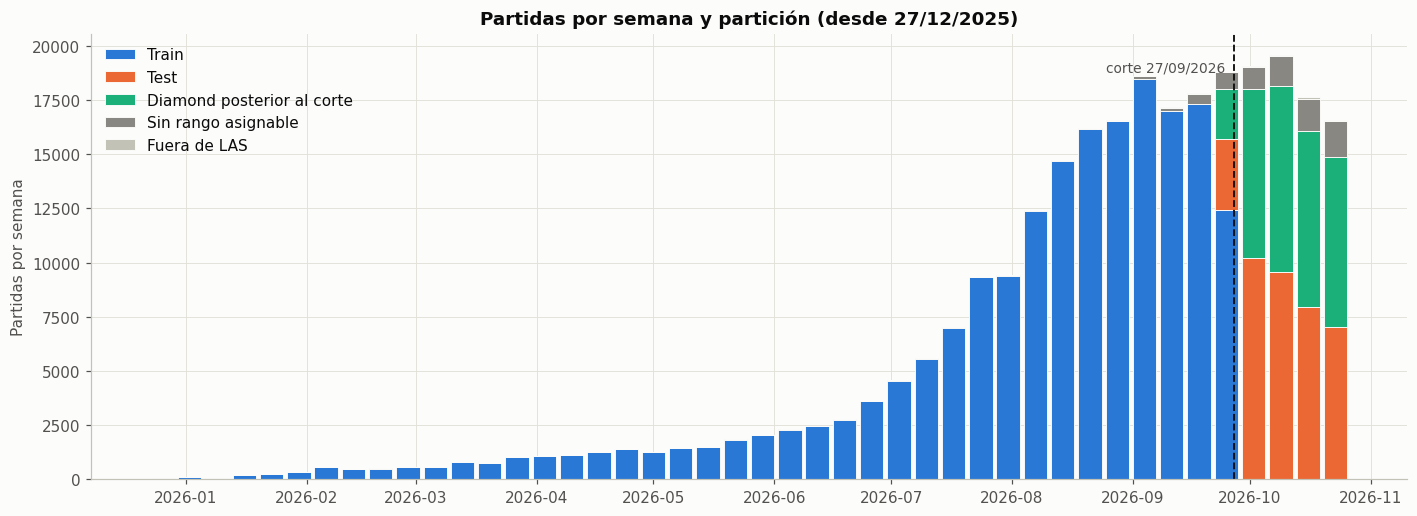

1,358 partidas anteriores al 27/12/2025 no entran en el gráfico.


In [2]:
resumen = (matches.groupby("split")
           .agg(partidas=("match_id", "size"), desde=("fecha", "min"), hasta=("fecha", "max"))
           .reindex([s for s in SPLIT_ORDER if s in set(matches["split"])]))
resumen["% partidas"] = (100 * resumen["partidas"] / resumen["partidas"].sum()).round(1)
resumen["personas"] = df_full.groupby("split", observed=True)["player_id"].nunique()
resumen["desde"] = resumen["desde"].dt.strftime("%Y-%m-%d")
resumen["hasta"] = resumen["hasta"].dt.strftime("%Y-%m-%d")
resumen.index = resumen.index.map(SPLIT_NAMES)
display(resumen[["partidas", "% partidas", "personas", "desde", "hasta"]])

print("Rango de la partida por partición:")
display(pd.crosstab(matches["split"].map(SPLIT_NAMES), matches["tier"], margins=True, margins_name="Total"))

# Partidas por semana. La cola vieja (2024-2025) es casi vacía: el gráfico arranca en
# el percentil RECORTE_COLA de la fecha y se informa cuántas partidas quedan afuera.
RECORTE_COLA = 0.005
fechas = matches["fecha"].sort_values()
desde_graf = fechas.iloc[int(RECORTE_COLA * len(fechas))].floor("D")
semanal = (matches[matches["fecha"] >= desde_graf]
           .groupby([pd.Grouper(key="fecha", freq="W-MON"), "split"]).size().unstack(fill_value=0))
semanal.index = semanal.index.tz_localize(None)

fig, ax = plt.subplots(figsize=(13, 4.8))
bottom = np.zeros(len(semanal))
for s in [s for s in SPLIT_ORDER if s in semanal.columns]:
    ax.bar(semanal.index, semanal[s], bottom=bottom, width=-6, align="edge", color=SPLIT_COLORS[s],
           label=SPLIT_NAMES[s], edgecolor="#fcfcfb", linewidth=0.6)
    bottom += semanal[s].to_numpy()
ax.axvline(CORTE.tz_localize(None), color=INK, linestyle="--", linewidth=1.2)
ax.annotate(f"corte {CORTE:%d/%m/%Y}", xy=(CORTE.tz_localize(None), bottom.max()), xytext=(-6, -4),
            textcoords="offset points", ha="right", va="top", fontsize=9, color=INK_2)
ax.set_title(f"Partidas por semana y partición (desde {desde_graf:%d/%m/%Y})")
ax.set_ylabel("Partidas por semana")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print(f"{int((matches['fecha'] < desde_graf).sum()):,} partidas anteriores al {desde_graf:%d/%m/%Y} "
      f"no entran en el gráfico.")

### 2. Calidad de datos

Se controlan las invariantes que tiene que cumplir el dataset, los valores faltantes y la
duración de las partidas. Las variables `@t` salen del timeline: una partida que terminó antes
del minuto `t` no tiene esa foto. Por eso el faltante de `@20` es **estructural** y no un error,
pero sesga cualquier análisis que use `@20`, porque quedan solo las partidas largas.

,casos
Partidas con un número de filas distinto de 10,0
Partidas sin exactamente 5 ganadores,54
"Filas duplicadas (match_id, participant_id)",0
"Persona repetida en una partida (match_id, player_id)",0
Equipos con resultado mezclado,0
Remakes (duración <= 300 s),0
Partidas fuera de LAS (sin prefijo LA2_),328
Filas con posición fuera de las 5 líneas (se sacan),55
Filas sin rango del jugador (fuera del padrón),262150


Partidas sin ningún ganador: 54, por fecha: {'2026-10-13': 52, '2026-06-26': 1, '2026-08-21': 1}; por partición: {'test': 24, 'diamante_despues': 21, 'sin_rango': 7, 'train': 2}. Se excluyen del análisis del target (sección 6).
Partidas fuera de LAS por servidor: {'BR1': 240, 'LA1': 58, 'NA1': 30}


,% mín.,% máx.,columnas
variables @10,0.51,0.51,9
variables @15,1.08,1.08,8
variables @20,7.14,7.14,8
player_rank,9.61,9.61,1
player_tier,9.61,9.61,1


,% filas sin dato,"sin dato, partida más corta","sin dato, partida más larga (timeline faltante)"
minuto,,,
10,0.51,13860,0
15,1.08,29503,0
20,7.14,194927,0


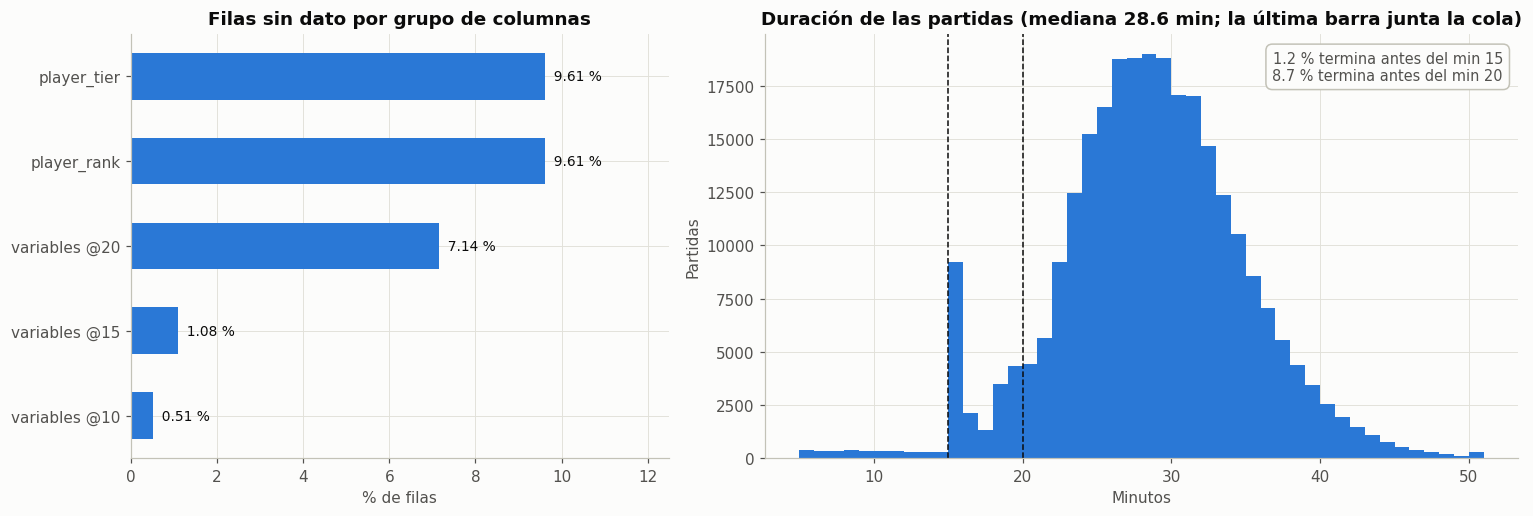

In [3]:
REMAKE_S = 300  # duración máxima de un remake (ROADMAP.md §2); se descartan al recolectar

resultado_equipo = df_full.groupby(["match_id", "team_id"])["win"].agg(["min", "max"])
checks = pd.Series({
    **checks_por_partida,
    "Filas duplicadas (match_id, participant_id)": int(df_full.duplicated(["match_id", "participant_id"]).sum()),
    "Persona repetida en una partida (match_id, player_id)": int(df_full.duplicated(["match_id", "player_id"]).sum()),
    "Equipos con resultado mezclado": int((resultado_equipo["min"] != resultado_equipo["max"]).sum()),
    f"Remakes (duración <= {REMAKE_S} s)": int((matches["game_duration"] <= REMAKE_S).sum()),
    "Partidas fuera de LAS (sin prefijo LA2_)": int((matches["servidor"] != "LA2").sum()),
    "Filas con posición fuera de las 5 líneas (se sacan)": n_fuera_de_linea,
    "Filas sin rango del jugador (fuera del padrón)": int(df_full["player_tier"].isna().sum()),
}, name="casos")
display(checks.to_frame())
fechas_sg = matches.loc[~matches["con_ganador"], "fecha"].dt.strftime("%Y-%m-%d").value_counts()
print(f"Partidas sin ningún ganador: {int((~matches['con_ganador']).sum())}, por fecha: {fechas_sg.to_dict()}; "
      f"por partición: {matches.loc[~matches['con_ganador'], 'split'].value_counts().to_dict()}. "
      "Se excluyen del análisis del target (sección 6).")
print("Partidas fuera de LAS por servidor:",
      matches.loc[matches["servidor"] != "LA2", "servidor"].value_counts().to_dict())

# Faltantes: las columnas del timeline faltan en bloque por minuto, así que se agrupan.
nulos = df_full.isna().mean().mul(100)
nulos = nulos[nulos > 0]
sufijo = nulos.index.str.rsplit("_", n=1).str[-1]
grupo = np.where(np.isin(sufijo, ["10", "15", "20"]), "variables @" + sufijo, nulos.index)
nulos_g = nulos.groupby(grupo).agg(["min", "max", "size"]).sort_values("max")
display(nulos_g.rename(columns={"min": "% mín.", "max": "% máx.", "size": "columnas"}).round(2))

filas = []
for t in (10, 15, 20):
    falta = df_full[f"gold_{t}"].isna()
    corta = df_full["game_duration"] < t * 60
    filas.append({"minuto": t, "% filas sin dato": 100 * falta.mean(),
                  "sin dato, partida más corta": int((falta & corta).sum()),
                  "sin dato, partida más larga (timeline faltante)": int((falta & ~corta).sum())})
display(pd.DataFrame(filas).set_index("minuto").round(2))

dur_min = matches["game_duration"] / 60
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax1.barh(nulos_g.index, nulos_g["max"], color=CATEGORICAL[0], height=0.55)
for y, v in enumerate(nulos_g["max"]):
    ax1.text(v, y, f"  {v:.2f} %", va="center", fontsize=9, color=INK)
ax1.set_xlim(0, nulos_g["max"].max() * 1.3)
ax1.set_title("Filas sin dato por grupo de columnas")
ax1.set_xlabel("% de filas")

dur_max = np.ceil(dur_min.quantile(0.999))
ax2.hist(dur_min.clip(upper=dur_max), bins=np.arange(np.floor(dur_min.min()), dur_max + 1), color=CATEGORICAL[0])
for t in (15, 20):
    ax2.axvline(t, color=INK, linestyle="--", linewidth=1)
ax2.text(0.98, 0.96, "\n".join(f"{100 * (dur_min < t).mean():.1f} % termina antes del min {t}" for t in (15, 20)),
         transform=ax2.transAxes, ha="right", va="top", fontsize=9.5, color=INK_2,
         bbox=dict(boxstyle="round,pad=0.45", facecolor="#fcfcfb", edgecolor="#c3c2b7"))
ax2.set_title(f"Duración de las partidas (mediana {dur_min.median():.1f} min; la última barra junta la cola)")
ax2.set_xlabel("Minutos")
ax2.set_ylabel("Partidas")
plt.tight_layout()
plt.show()

### 3. Parches

Partidas por parche (`Major.Minor`), en orden cronológico y separadas por partición. Los
parches con menos de `UMBRAL_PARCHE` de las partidas se juntan en "Otros". Como el test es el
tramo más reciente, se concentra en los últimos parches: un modelo entrenado con el meta del
train se evalúa con otro meta.

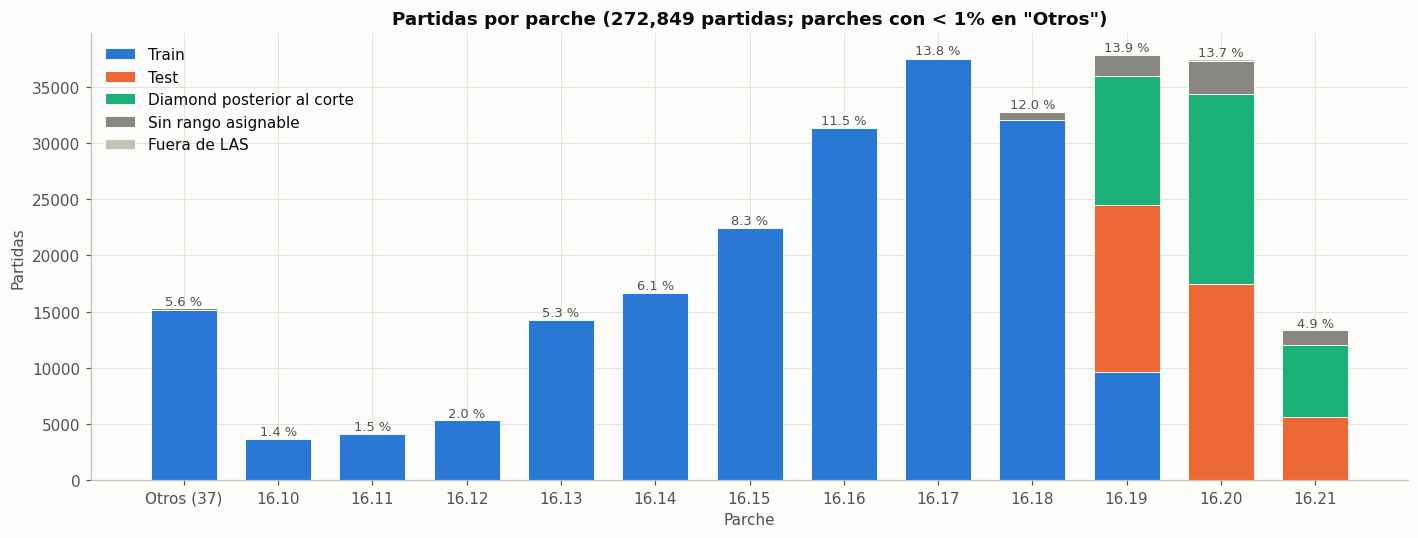

In [4]:
UMBRAL_PARCHE = 0.01

por_parche = matches.groupby(["patch", "split"], observed=True).size().unstack(fill_value=0)
por_parche = por_parche.loc[sorted(por_parche.index, key=patch_key)]
chicos = por_parche.sum(axis=1) < UMBRAL_PARCHE * por_parche.to_numpy().sum()
tabla = por_parche[~chicos]
if chicos.any():
    tabla = pd.concat([por_parche[chicos].sum().to_frame(f"Otros ({int(chicos.sum())})").T, tabla])
total = tabla.sum(axis=1)

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(tabla))
bottom = np.zeros(len(tabla))
for s in [s for s in SPLIT_ORDER if s in tabla.columns]:
    ax.bar(x, tabla[s], bottom=bottom, color=SPLIT_COLORS[s], label=SPLIT_NAMES[s], width=0.7,
           edgecolor="#fcfcfb", linewidth=0.6)
    bottom += tabla[s].to_numpy()
for xi, tot in zip(x, total):
    ax.text(xi, tot, f"{100 * tot / total.sum():.1f} %", ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax.set_xticks(x, tabla.index.astype(str), rotation=0)
ax.set_title(f"Partidas por parche ({total.sum():,} partidas; parches con < {UMBRAL_PARCHE:.0%} en \"Otros\")")
ax.set_xlabel("Parche")
ax.set_ylabel("Partidas")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 4. Cobertura del padrón por ELO

Para cada escalón del padrón activo (`players.csv`): qué porcentaje de los jugadores llega a
cada umbral de partidas registradas, junto con la media (μ) y la mediana (M) de partidas por
jugador. El rango es el que tiene hoy cada jugador en el padrón. Las partidas se cuentan sobre
todo el dataset, sin separar por partición (eso queda para la sección 5).

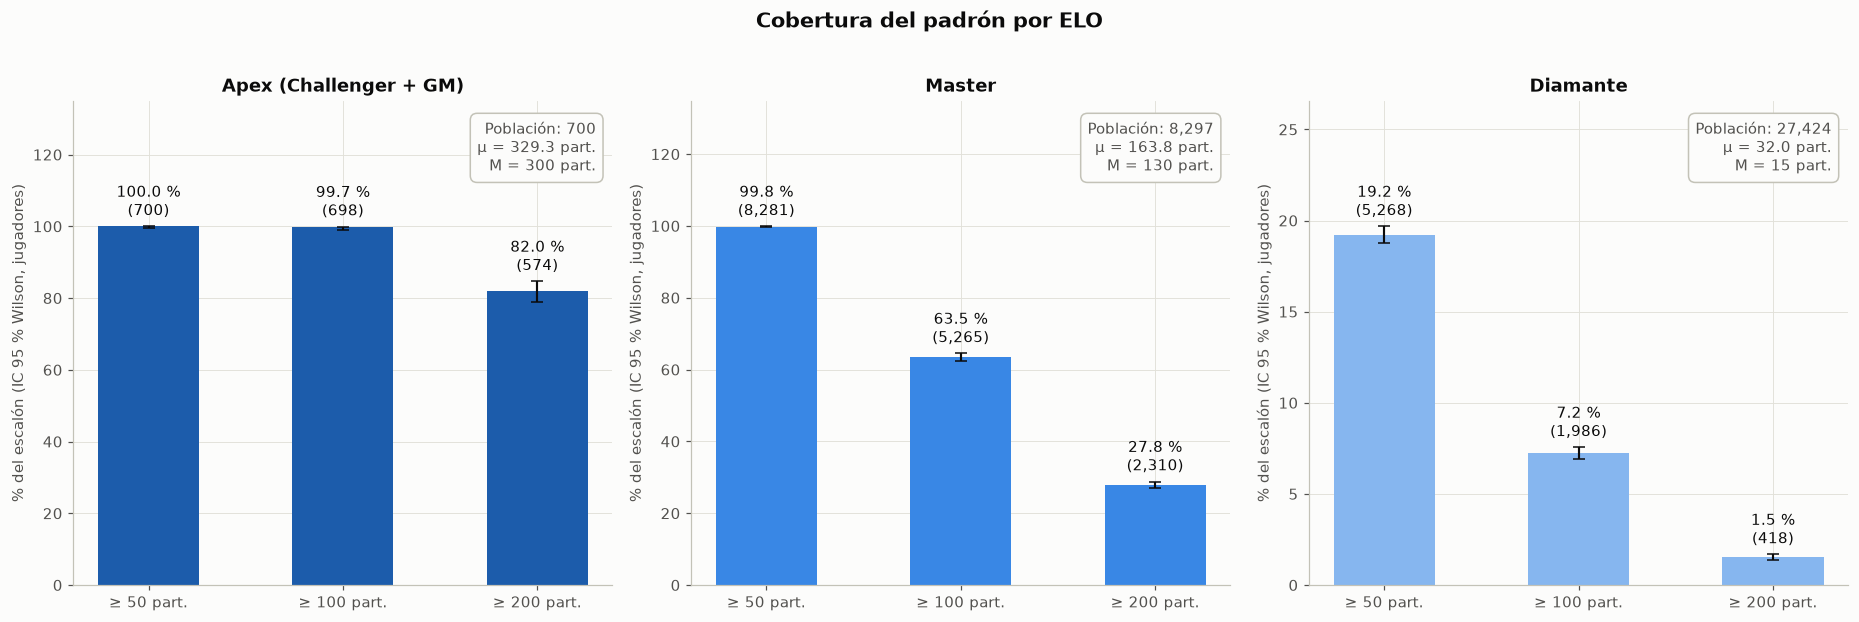

,jugadores,media,mediana,% con ≥ 50,% con ≥ 100,% con ≥ 200
escalón,,,,,,
Apex (Challenger + GM),700,329.3,300.0,100.0,99.7,82.0
Master,8297,163.8,130.0,99.8,63.5,27.8
Diamante,27424,32.0,15.0,19.2,7.2,1.5


In [5]:
UMBRALES_COBERTURA = [50, 100, 200]
GRUPOS_ELO = {
    "Apex (Challenger + GM)": ["CHALLENGER", "GRANDMASTER"],
    "Master": ["MASTER"],
    "Diamante": ["DIAMOND"],
}
COLOR_ELO = {"Apex (Challenger + GM)": TIER_COLORS["GRANDMASTER"], "Master": TIER_COLORS["MASTER"],
             "Diamante": TIER_COLORS["DIAMOND"]}

fig, axes = plt.subplots(1, len(GRUPOS_ELO), figsize=(17, 5.5))
filas = []
for ax, (nombre, tiers) in zip(axes, GRUPOS_ELO.items()):
    g = df_players.loc[df_players["player_tier"].isin(tiers), "games_recorded"]
    counts = [int((g >= t).sum()) for t in UMBRALES_COBERTURA]
    pcts = [100 * c / len(g) for c in counts]
    filas.append({"escalón": nombre, "jugadores": len(g), "media": g.mean(), "mediana": g.median(),
                  **{f"% con ≥ {t}": p for t, p in zip(UMBRALES_COBERTURA, pcts)}})

    etiquetas = [f"≥ {t} part." for t in UMBRALES_COBERTURA]
    p_arr = np.array(counts, dtype=float) / len(g)
    lo_w, hi_w = wilson_ci(p_arr, np.full(len(counts), len(g), dtype=float))
    lo_p, hi_p = 100.0 * lo_w, 100.0 * hi_w
    bars = ax.bar(etiquetas, pcts, color=COLOR_ELO[nombre], width=0.52)
    ax.errorbar(np.arange(len(etiquetas)), pcts,
                yerr=[np.maximum(0.0, np.array(pcts) - lo_p), np.maximum(0.0, hi_p - np.array(pcts))],
                fmt="none", ecolor=INK, elinewidth=1.4, capsize=4, zorder=5)
    ax.set_ylim(0, max(float(hi_p.max()), 1.0) * 1.35)
    for bar, pct, cnt, hp in zip(bars, pcts, counts, hi_p):
        ax.annotate(f"{pct:.1f} %\n({cnt:,})", xy=(bar.get_x() + bar.get_width() / 2, hp),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=10, color=INK)
    ax.set_title(nombre)
    ax.set_ylabel("% del escalón (IC 95 % Wilson, jugadores)")
    ax.text(0.97, 0.96, f"Población: {len(g):,}\nμ = {g.mean():.1f} part.\nM = {g.median():.0f} part.",
            transform=ax.transAxes, ha="right", va="top", fontsize=10, color=INK_2,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="#fcfcfb", edgecolor="#c3c2b7"))
plt.suptitle("Cobertura del padrón por ELO", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()
display(pd.DataFrame(filas).set_index("escalón").round(1))

### 5. Partidas por jugador en cada partición

Cuántas partidas tiene cada jugador del padrón **dentro de cada partición**, separando
Master+ de Diamond según el rango actual del jugador. La curva da, para cada `n`, qué
porcentaje del padrón del grupo tiene al menos `n` partidas en esa partición. Esto determina
cuántos jugadores tienen historial suficiente en el train para construirles un perfil y
cuántos de ellos se pueden evaluar en el test.

Las particiones se definen por partida, no por jugador. Un jugador Diamond puede tener
partidas en el test (lobbies Master+ con jugadores Diamond) y un jugador Master puede tenerlas
en "Diamond posterior al corte".

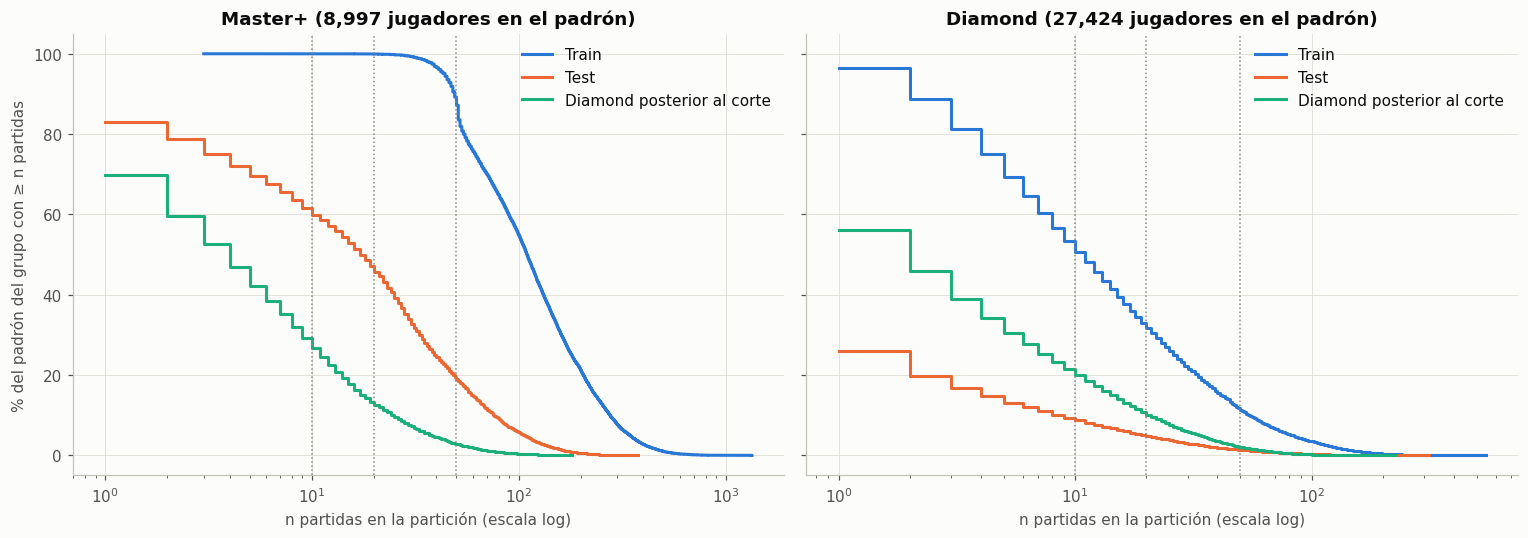

padrón del grupo  con ≥ 1  \
grupo   partición                                               
Master+ Train                                   8997     8997   
        Test                                    8997     7476   
        Diamond posterior al corte              8997     6283   
Diamond Train                                  27424    26424   
        Test                                   27424     7099   
        Diamond posterior al corte             27424    15394   

                                    mediana (de los que tienen ≥ 1)  con ≥ 10  \
grupo   partición                                                               
Master+ Train                                                 109.0      8996   
        Test                                                   23.0      5392   
        Diamond posterior al corte                              7.0      2395   
Diamond Train                                                  10.0     13911   
        Test                                                    5.0      2394   
        Diamond posterior al corte                              5.0      5483   

                                    con ≥ 20  con ≥ 50  
grupo   partición                                       
Master+ Train                           8990      7842  
        Test                            4119      1723  
        Diamond posterior al corte      1137       260  
Diamond Train                           8703      3134  
        Test                            1314       379  
        Diamond posterior al corte      2786       575

In [6]:
UMBRALES_JUG = [10, 20, 50]
SPLITS_JUG = ["train", "test", "diamante_despues"]
GRUPOS_JUG = ["Master+", "Diamond"]

grupo_jug = df_players.set_index("player_id")["player_tier"].map(
    lambda t: "Master+" if t in MASTER_PLUS else ("Diamond" if t == "DIAMOND" else None)).dropna()
n_padron = grupo_jug.value_counts()
por_jug = (df_full.loc[df_full["player_id"].isin(grupo_jug.index) & df_full["split"].isin(SPLITS_JUG)]
           .groupby(["player_id", "split"], observed=True).size().rename("partidas").reset_index())
por_jug["grupo"] = por_jug["player_id"].map(grupo_jug)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
filas = []
for ax, g in zip(axes, GRUPOS_JUG):
    sub_g = por_jug[por_jug["grupo"] == g]
    for s in SPLITS_JUG:
        x = np.sort(sub_g.loc[sub_g["split"] == s, "partidas"].to_numpy())
        if len(x) == 0:
            continue
        n_vals = np.unique(x)
        pct = 100 * (len(x) - np.searchsorted(x, n_vals, side="left")) / n_padron[g]
        ax.step(n_vals, pct, where="post", color=SPLIT_COLORS[s], linewidth=2, label=SPLIT_NAMES[s])
        filas.append({"grupo": g, "partición": SPLIT_NAMES[s], "padrón del grupo": int(n_padron[g]),
                      "con ≥ 1": len(x), "mediana (de los que tienen ≥ 1)": float(np.median(x)),
                      **{f"con ≥ {u}": int((x >= u).sum()) for u in UMBRALES_JUG}})
    for u in UMBRALES_JUG:
        ax.axvline(u, color=MUTED, linestyle=":", linewidth=1)
    ax.set_xscale("log")
    ax.set_title(f"{g} ({n_padron[g]:,} jugadores en el padrón)")
    ax.set_xlabel("n partidas en la partición (escala log)")
    ax.legend(loc="upper right")
axes[0].set_ylabel("% del padrón del grupo con ≥ n partidas")
plt.tight_layout()
plt.show()
display(pd.DataFrame(filas).set_index(["grupo", "partición"]))

### 6. El target: victoria por lado del mapa

El target de los modelos de partida es qué lado gana. Si un lado gana más de la mitad de las
veces, "siempre ese lado" es el piso que cualquier modelo tiene que superar. También se mira si
la ventaja depende de la partición o de la duración. Las barras de error son el IC 95 %. Se
excluyen las partidas sin ganador (sección 2).

Victoria del lado azul: 48.36 % ± 0.19 pp (IC 95 %, n = 272,795). Siempre rojo acierta el 51.64 %.


partidas  % azul  ± IC 95
partición           Train                         192102   48.20     0.22
                    Test                           37989   47.49     0.50
                    Diamond posterior al corte     34680   49.90     0.53
                    Sin rango asignable             7696   49.73     1.12
                    Fuera de LAS                     328   46.04     5.39
rango de la partida CHALLENGER                      2293   47.62     2.04
                    DIAMOND                        78844   49.42     0.35
                    GRANDMASTER                    13011   47.76     0.86
                    MASTER                        170623   47.87     0.24
                    SIN_RANGO                       7696   49.73     1.12
                    —                                328   46.04     5.39

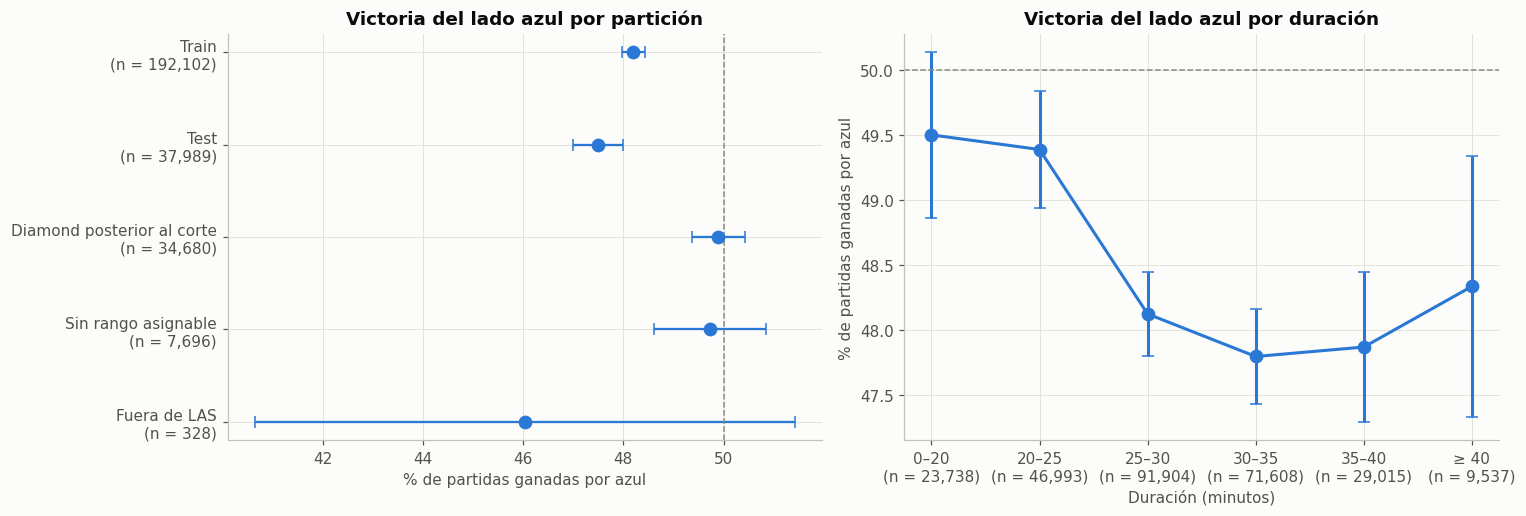

In [7]:
BORDES_DURACION = [0, 20, 25, 30, 35, 40, np.inf]  # minutos

# Sin las partidas que no tienen ganador (sección 2): ahí "azul perdió" no es cierto.
matches_t = matches[matches["con_ganador"]]
p, n = matches_t["blue_win"].mean(), len(matches_t)
print(f"Victoria del lado azul: {100 * p:.2f} % ± {100 * ic95(p, n):.2f} pp (IC 95 %, n = {n:,}). "
      f"Siempre rojo acierta el {100 * (1 - p):.2f} %.")

por_split = (matches_t.groupby("split")["blue_win"].agg(["mean", "size"])
             .reindex([s for s in SPLIT_ORDER if s in set(matches_t["split"])]))
por_tier = matches_t.groupby("tier")["blue_win"].agg(["mean", "size"])
display(pd.concat({"partición": por_split.rename(index=SPLIT_NAMES), "rango de la partida": por_tier})
        .assign(**{"% azul": lambda d: 100 * d["mean"], "± IC 95": lambda d: 100 * ic95(d["mean"], d["size"])})
        .drop(columns="mean").rename(columns={"size": "partidas"}).round(2))

tramo = pd.cut(matches_t["game_duration"] / 60, BORDES_DURACION, right=False)
por_dur = matches_t.groupby(tramo, observed=True)["blue_win"].agg(["mean", "size"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
y = np.arange(len(por_split))
ax1.errorbar(100 * por_split["mean"], y, xerr=100 * ic95(por_split["mean"], por_split["size"]),
             fmt="o", color=CATEGORICAL[0], markersize=8, capsize=4)
ax1.axvline(50, color=MUTED, linestyle="--", linewidth=1)
ax1.set_yticks(y, [f"{SPLIT_NAMES[s]}\n(n = {k:,})" for s, k in por_split["size"].items()])
ax1.invert_yaxis()
ax1.set_title("Victoria del lado azul por partición")
ax1.set_xlabel("% de partidas ganadas por azul")

etiquetas = [f"{int(iv.left)}–{int(iv.right)}" if np.isfinite(iv.right) else f"≥ {int(iv.left)}"
             for iv in por_dur.index]
x = np.arange(len(por_dur))
ax2.errorbar(x, 100 * por_dur["mean"], yerr=100 * ic95(por_dur["mean"], por_dur["size"]),
             fmt="o-", color=CATEGORICAL[0], markersize=8, capsize=4, linewidth=2)
ax2.axhline(50, color=MUTED, linestyle="--", linewidth=1)
ax2.set_xticks(x, [f"{e}\n(n = {k:,})" for e, k in zip(etiquetas, por_dur["size"])])
ax2.set_title("Victoria del lado azul por duración")
ax2.set_xlabel("Duración (minutos)")
ax2.set_ylabel("% de partidas ganadas por azul")
plt.tight_layout()
plt.show()

## Parte B. Campeones y draft

Desde acá el EDA trabaja **solo con el train**. Los agregados por jugador y por campeón
salen de `data/splits/train/` (`players.csv` y `champions_by_lane.csv` calculados solo con
partidas de train, `export_to_csv.py --target splits`, §9.S.14), no del volcado completo,
que mezcla las partidas del test.

Quedan afuera el test y también el resto de las particiones (Diamond posterior al corte,
sin rango asignable y fuera de LAS): las posteriores al corte comparten período y parches
con el test, así que mostrarían su meta por otro camino.

In [8]:
TRAIN_DIR = SPLIT_DIR / "train"

ids_train = set(matches.loc[matches["split"] == "train", "match_id"])
df_full = df_full[df_full["split"] == "train"].reset_index(drop=True)
lane_rows = df_full
matches_train = matches[matches["split"] == "train"]
df_matchups = df_matchups[df_matchups["match_id"].astype(str).isin(ids_train)].reset_index(drop=True)
df_players = pd.read_csv(TRAIN_DIR / "players.csv")
df_champions = pd.read_csv(TRAIN_DIR / "champions_by_lane.csv")

print(f"Train: {len(matches_train):,} partidas ({100 * len(matches_train) / len(matches):.1f} % del total), "
      f"{len(df_full):,} filas, {df_full['player_id'].nunique():,} personas, "
      f"del {matches_train['fecha'].min():%d/%m/%Y} al {matches_train['fecha'].max():%d/%m/%Y}.")
print(f"matchups_1v1: {len(df_matchups):,} | players.csv (train): {len(df_players):,} "
      f"| champions_by_lane.csv (train): {len(df_champions):,}")
print("Particiones excluidas:", matches.loc[matches["split"] != "train", "split"].map(SPLIT_NAMES)
      .value_counts().to_dict())

Train: 192,104 partidas (70.4 % del total), 1,921,003 filas, 56,619 personas, del 06/11/2024 al 26/09/2026.
matchups_1v1: 960,637 | players.csv (train): 35,421 | champions_by_lane.csv (train): 861
Particiones excluidas: {'Test': 38013, 'Diamond posterior al corte': 34701, 'Sin rango asignable': 7703, 'Fuera de LAS': 328}


### 7. Top 15 campeones más jugados, por rol

Total de partidas de cada campeón, separado por la posición en la que se jugó. Los números
dentro de la barra se muestran solo en los segmentos que superan `ETIQUETA_MIN` del campeón
más jugado.

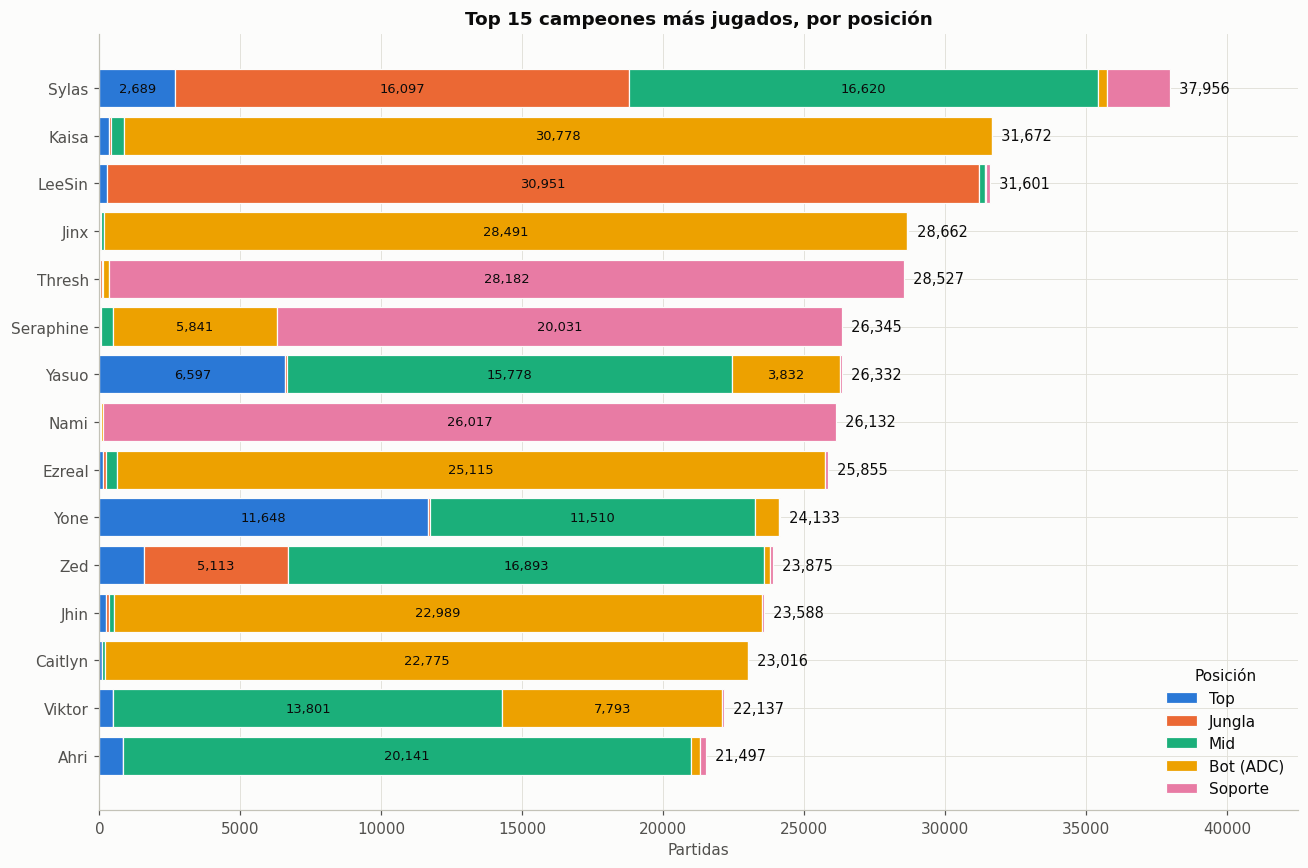

In [9]:
TOP_CAMPEONES = 15
ETIQUETA_MIN = 0.06

pivot_df = (df_champions.pivot_table(index="champion_name", columns="lane", values="games_played",
                                     aggfunc="sum", fill_value=0)
            .reindex(columns=LANES, fill_value=0))
pivot_df["total"] = pivot_df[LANES].sum(axis=1)
top = pivot_df.nlargest(TOP_CAMPEONES, "total").iloc[::-1]
seg_min = ETIQUETA_MIN * top["total"].max()

fig, ax = plt.subplots(figsize=(12, 8))
left = np.zeros(len(top))
for lane in LANES:
    vals = top[lane].to_numpy()
    ax.barh(top.index, vals, left=left, color=LANE_COLORS[lane], label=LANE_NAMES[lane],
            edgecolor="#fcfcfb", linewidth=0.8)
    for i, v in enumerate(vals):
        if v >= seg_min:
            ax.text(left[i] + v / 2, i, f"{int(v):,}", ha="center", va="center", fontsize=8.5, color=INK)
    left += vals
for i, tot in enumerate(top["total"]):
    ax.text(tot, i, f"  {int(tot):,}", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, top["total"].max() * 1.12)
ax.set_title(f"Top {TOP_CAMPEONES} campeones más jugados, por posición")
ax.set_xlabel("Partidas")
ax.legend(title="Posición", loc="lower right")
plt.tight_layout()
plt.show()

### 8. Top 5 por línea: campeones y matchups

A la izquierda, los campeones más jugados en cada posición y su winrate. A la derecha, los
enfrentamientos directos de línea más repetidos, sin importar el lado. El porcentaje es el
winrate del primer campeón del par.

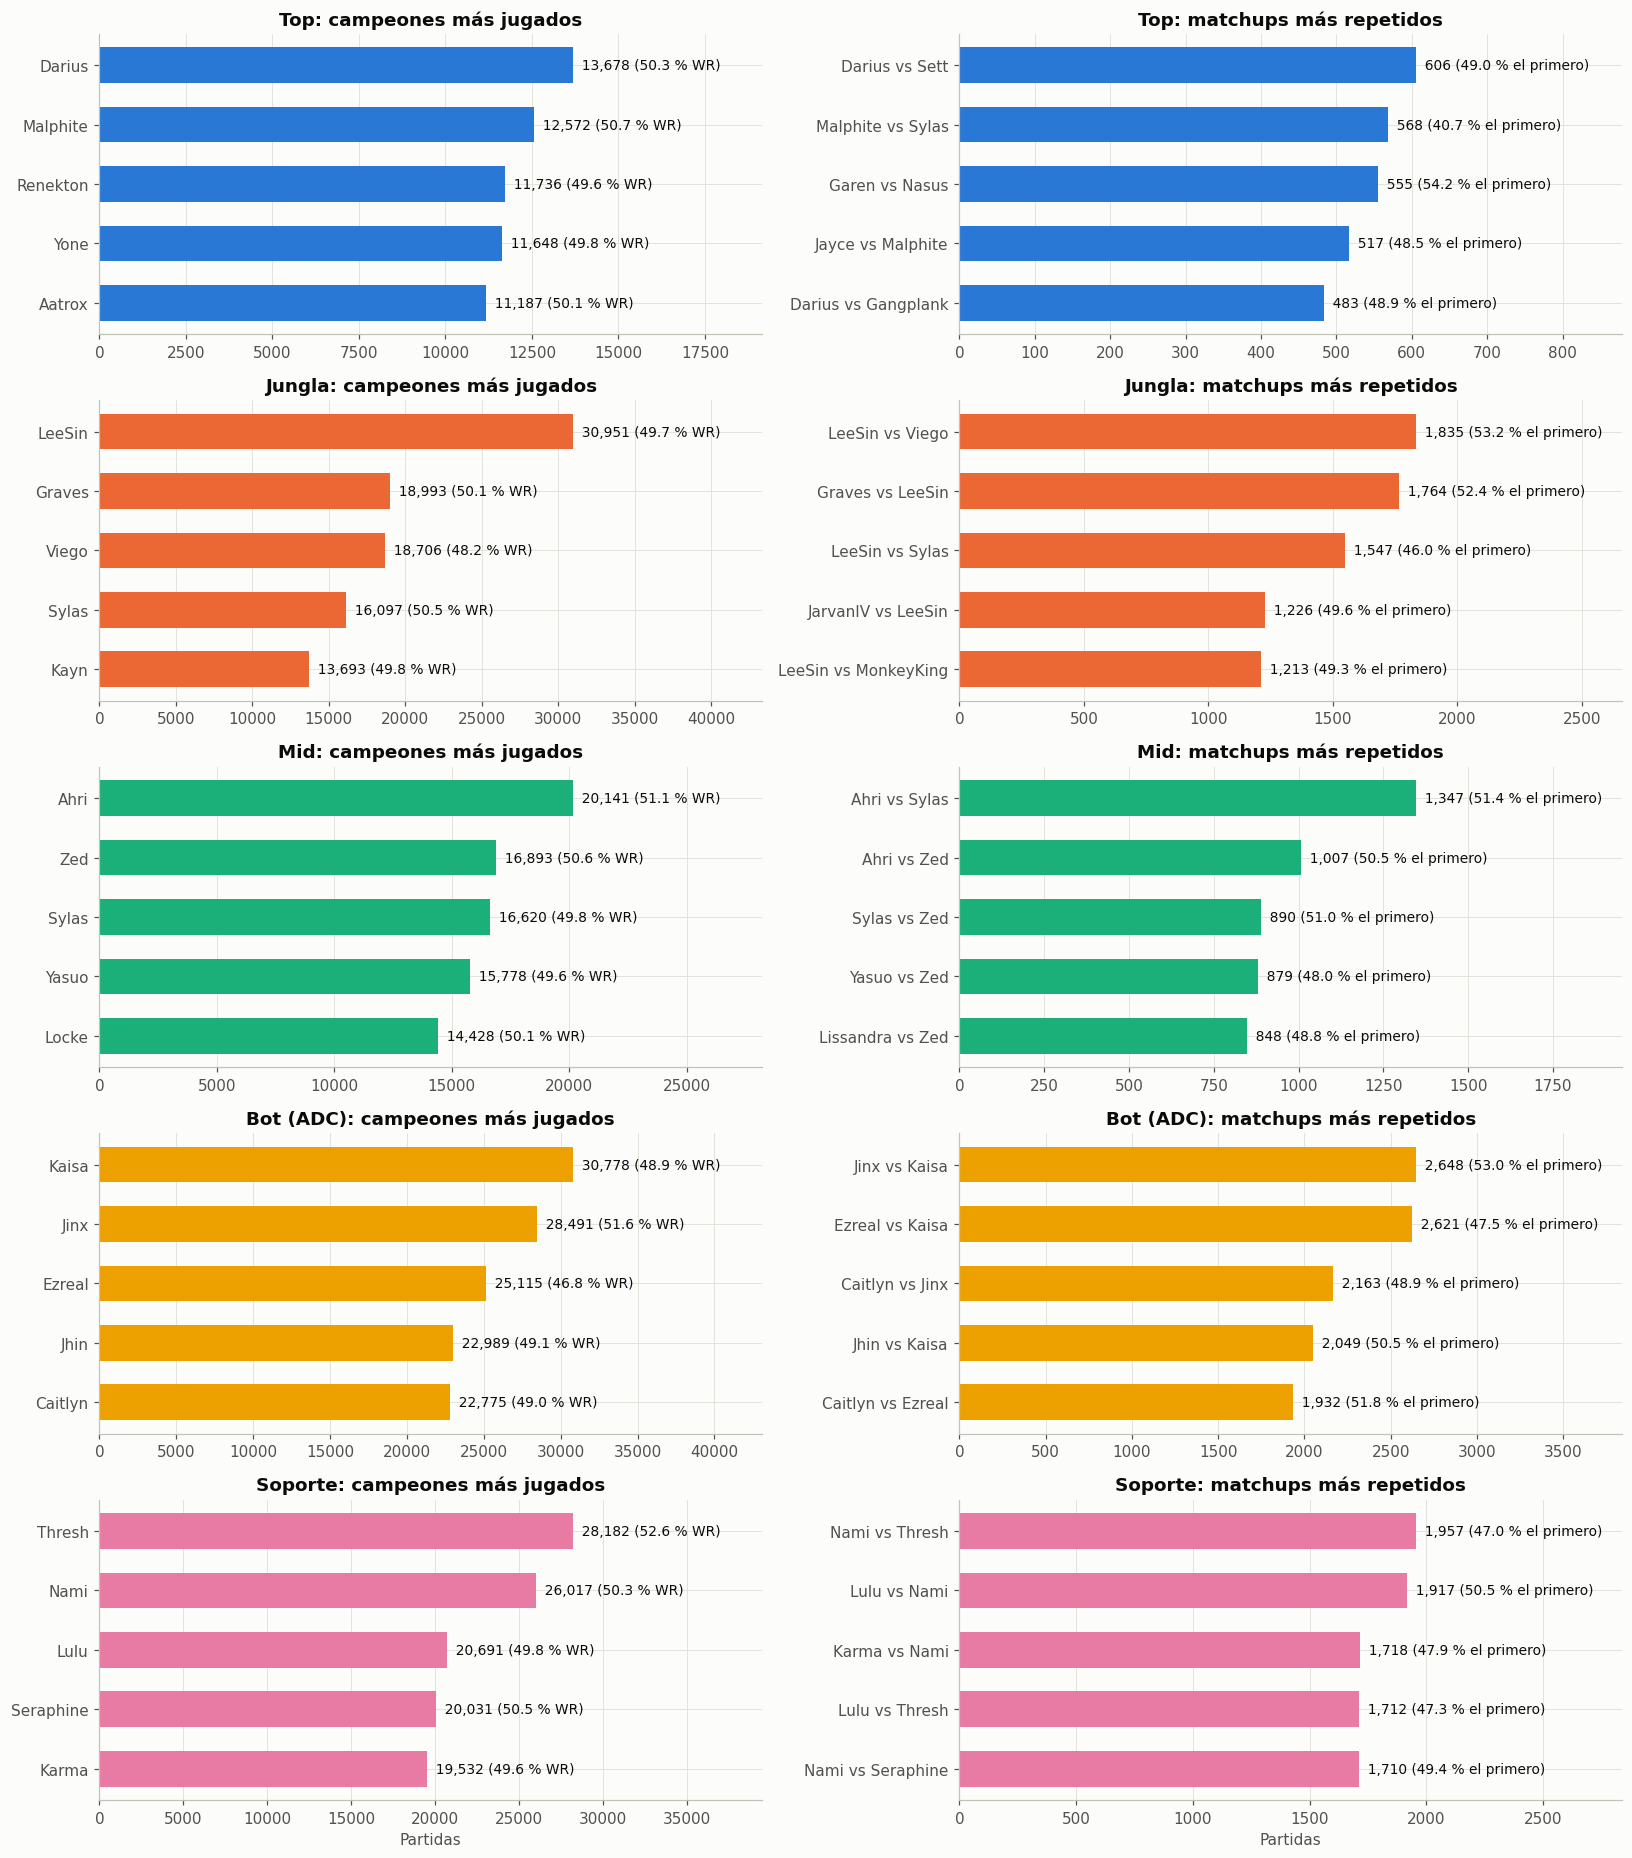

In [10]:
TOP_N = 5

b = df_matchups["blue_champion"].astype(str)
r = df_matchups["red_champion"].astype(str)
azul_primero = b <= r
df_matchups["matchup_pair"] = np.where(azul_primero, b + " vs " + r, r + " vs " + b)
# Victoria del primer campeón del par (orden alfabético)
df_matchups["primero_gana"] = np.where(azul_primero, df_matchups["blue_win"], 1 - df_matchups["blue_win"])

fig, axes = plt.subplots(len(LANES), 2, figsize=(15, 17))
for i, lane in enumerate(LANES):
    champs = df_champions[df_champions["lane"] == lane].nlargest(TOP_N, "games_played").iloc[::-1]
    ax = axes[i, 0]
    ax.barh(champs["champion_name"], champs["games_played"], color=LANE_COLORS[lane], height=0.6)
    for y, (g, wr) in enumerate(zip(champs["games_played"], champs["winrate_pct"])):
        ax.text(g, y, f"  {g:,} ({wr:.1f} % WR)", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, champs["games_played"].max() * 1.4)
    ax.set_title(f"{LANE_NAMES[lane]}: campeones más jugados")

    pares = (df_matchups[df_matchups["lane"] == lane].groupby("matchup_pair")["primero_gana"]
             .agg(["size", "mean"]).nlargest(TOP_N, "size").iloc[::-1])
    ax = axes[i, 1]
    ax.barh(pares.index, pares["size"], color=LANE_COLORS[lane], height=0.6)
    for y, (g, wr) in enumerate(zip(pares["size"], pares["mean"])):
        ax.text(g, y, f"  {g:,} ({100 * wr:.1f} % el primero)", va="center", fontsize=9, color=INK)
    ax.set_xlim(0, pares["size"].max() * 1.45)
    ax.set_title(f"{LANE_NAMES[lane]}: matchups más repetidos")
for ax in axes[-1]:
    ax.set_xlabel("Partidas")
plt.tight_layout()
plt.show()

### 9. Sinergias dentro del equipo

Pares de campeones del mismo equipo que más se repiten en tres núcleos: bot (ADC + soporte),
jungla + top y jungla + mid. Cada par se arma con la posición que reporta Riot. En bot, si
Riot invirtió los roles (el ADC figura como soporte), el par se reordena. Se toma como ADC a
todo campeón con al menos `UMBRAL_ADC` de sus partidas en `BOTTOM`, calculado sobre los datos
y no con una lista fija.

25 campeones con ≥ 50% de sus partidas en BOTTOM se toman como ADC.


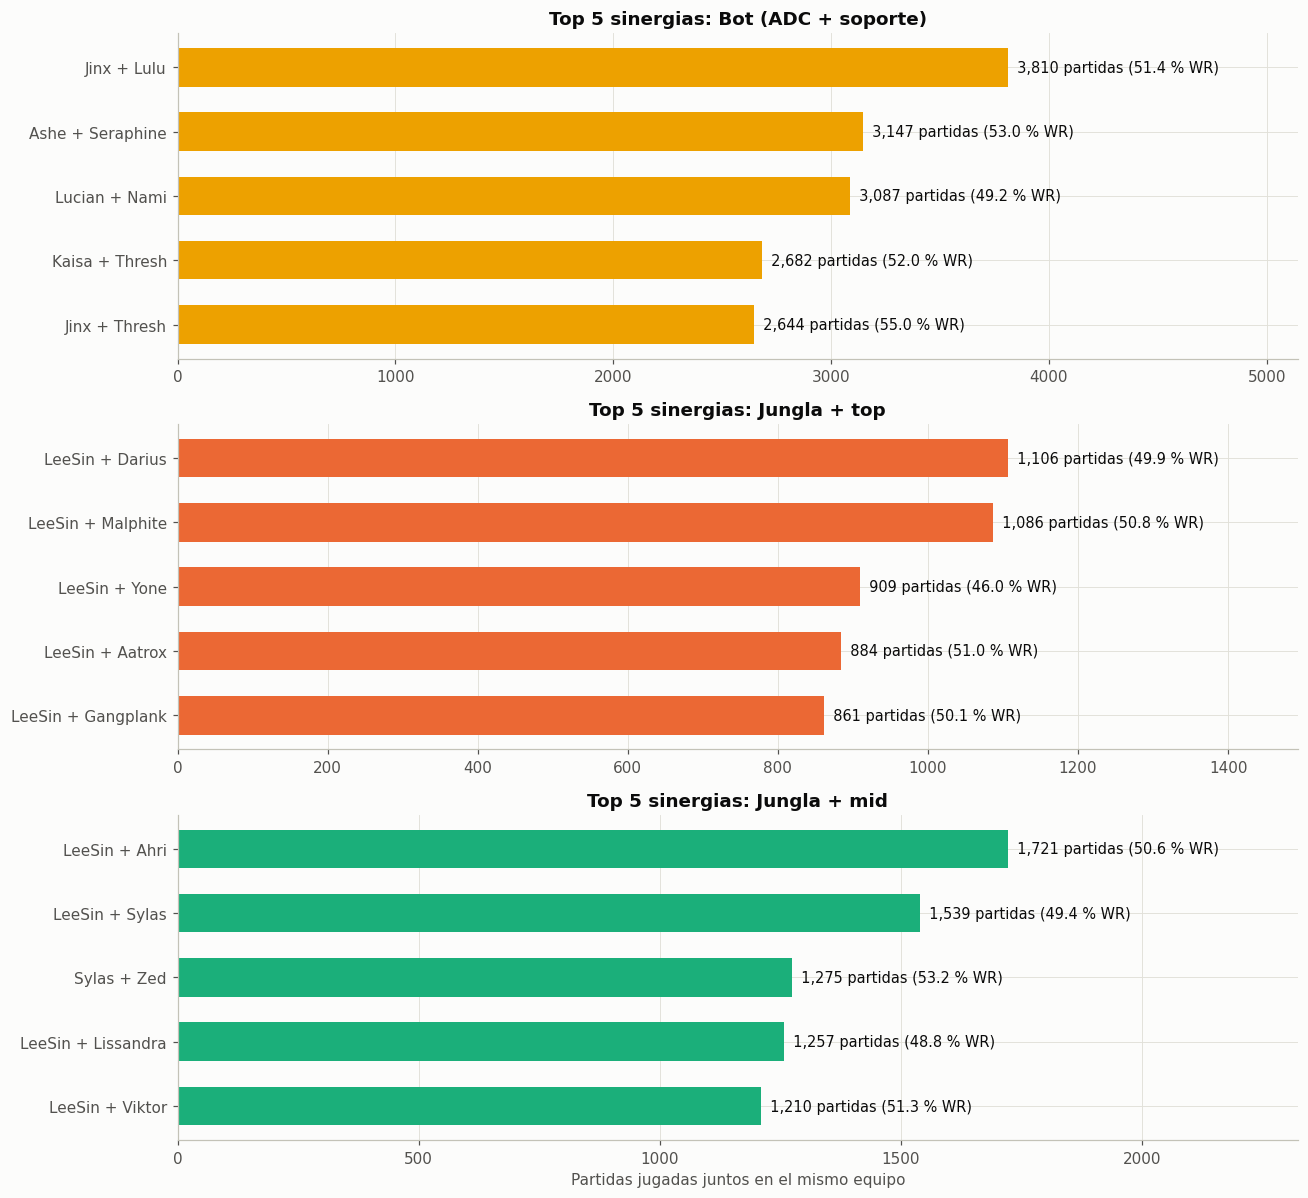

In [11]:
UMBRAL_ADC = 0.5
TOP_N = 5

por_linea = (df_champions.pivot_table(index="champion_name", columns="lane", values="games_played",
                                      aggfunc="sum", fill_value=0).reindex(columns=LANES, fill_value=0))
share_bot = por_linea["BOTTOM"] / por_linea.sum(axis=1)
ADCS = set(share_bot[share_bot >= UMBRAL_ADC].index)
print(f"{len(ADCS)} campeones con ≥ {UMBRAL_ADC:.0%} de sus partidas en BOTTOM se toman como ADC.")

# Un equipo por fila y una columna por posición; se descartan los equipos con una posición repetida.
cols_eq = lane_rows[["match_id", "team_id", "lane", "champion_name"]]
por_equipo = (cols_eq.assign(champion_name=cols_eq["champion_name"].astype(str), lane=cols_eq["lane"].astype(str))
              .drop_duplicates(["match_id", "team_id", "lane"], keep=False)
              .pivot(index=["match_id", "team_id"], columns="lane", values="champion_name"))
por_equipo["win"] = df_full.drop_duplicates(["match_id", "team_id"]).set_index(["match_id", "team_id"])["win"]


def top_pares(col_a, col_b, reordenar=None):
    d = por_equipo[[col_a, col_b, "win"]].dropna(subset=[col_a, col_b])
    a, b = d[col_a], d[col_b]
    if reordenar is not None:
        a, b = reordenar(a, b)
    return (d.assign(par=a + " + " + b).groupby("par")["win"].agg(partidas="size", wr="mean")
            .nlargest(TOP_N, "partidas").iloc[::-1])


def adc_primero(bot, sup):
    invertido = ~bot.isin(ADCS) & sup.isin(ADCS)
    return bot.where(~invertido, sup), sup.where(~invertido, bot)


nucleos = [
    ("Bot (ADC + soporte)", top_pares("BOTTOM", "UTILITY", adc_primero), LANE_COLORS["BOTTOM"]),
    ("Jungla + top", top_pares("JUNGLE", "TOP"), LANE_COLORS["JUNGLE"]),
    ("Jungla + mid", top_pares("JUNGLE", "MIDDLE"), LANE_COLORS["MIDDLE"]),
]
fig, axes = plt.subplots(len(nucleos), 1, figsize=(12, 11))
for ax, (titulo, d, color) in zip(axes, nucleos):
    ax.barh(d.index, d["partidas"], color=color, height=0.6)
    for y, (g, wr) in enumerate(zip(d["partidas"], d["wr"])):
        ax.text(g, y, f"  {g:,} partidas ({100 * wr:.1f} % WR)", va="center", fontsize=9.5, color=INK)
    ax.set_xlim(0, d["partidas"].max() * 1.35)
    ax.set_title(f"Top {TOP_N} sinergias: {titulo}")
axes[-1].set_xlabel("Partidas jugadas juntos en el mismo equipo")
plt.tight_layout()
plt.show()

### 10. Meta por parche: trayectorias de winrate

Se toman los parches con al menos `UMBRAL_PARCHE_META` de las partidas. Un campeón entra si
tiene al menos `MIN_PATCH_GAMES` partidas en una fracción `FRAC_PARCHES_PRESENTE` de esos
parches y `MIN_TOTAL_GAMES` en total. El winrate de un parche solo se usa si ese parche llega
a `MIN_PATCH_GAMES` partidas.

- **Gráfico 1:** los campeones con mayor rango de winrate entre parches (máximo − mínimo).
- **Gráfico 2:** los mayores saltos positivos y negativos entre parches consecutivos.

Con `MIN_PATCH_GAMES` partidas, el IC 95 % de un winrate sigue siendo amplio (la celda lo
imprime): los giros chicos pueden ser ruido muestral.

Parches con ≥ 5% de las partidas: 16.13, 16.14, 16.15, 16.16, 16.17, 16.18 (80.3% del train).
Con 80 partidas, el IC 95 % de un winrate de 50 % es ± 11.0 pp.


173 campeones cumplen el filtro.


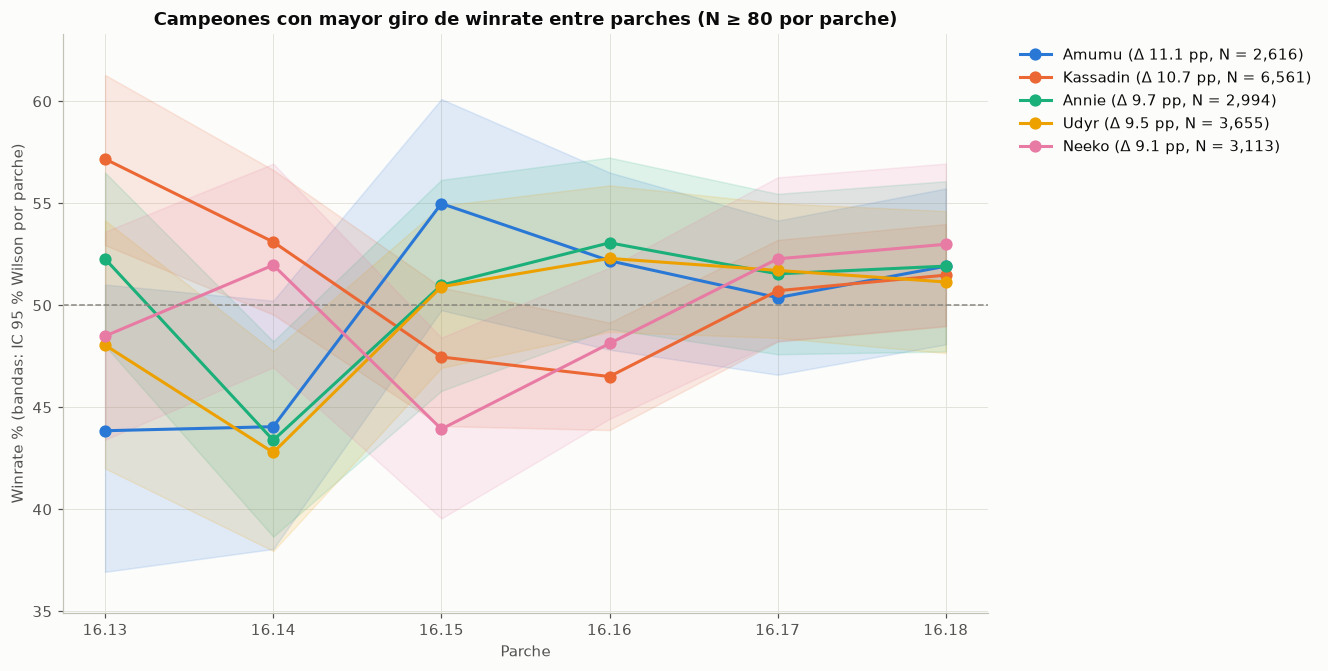

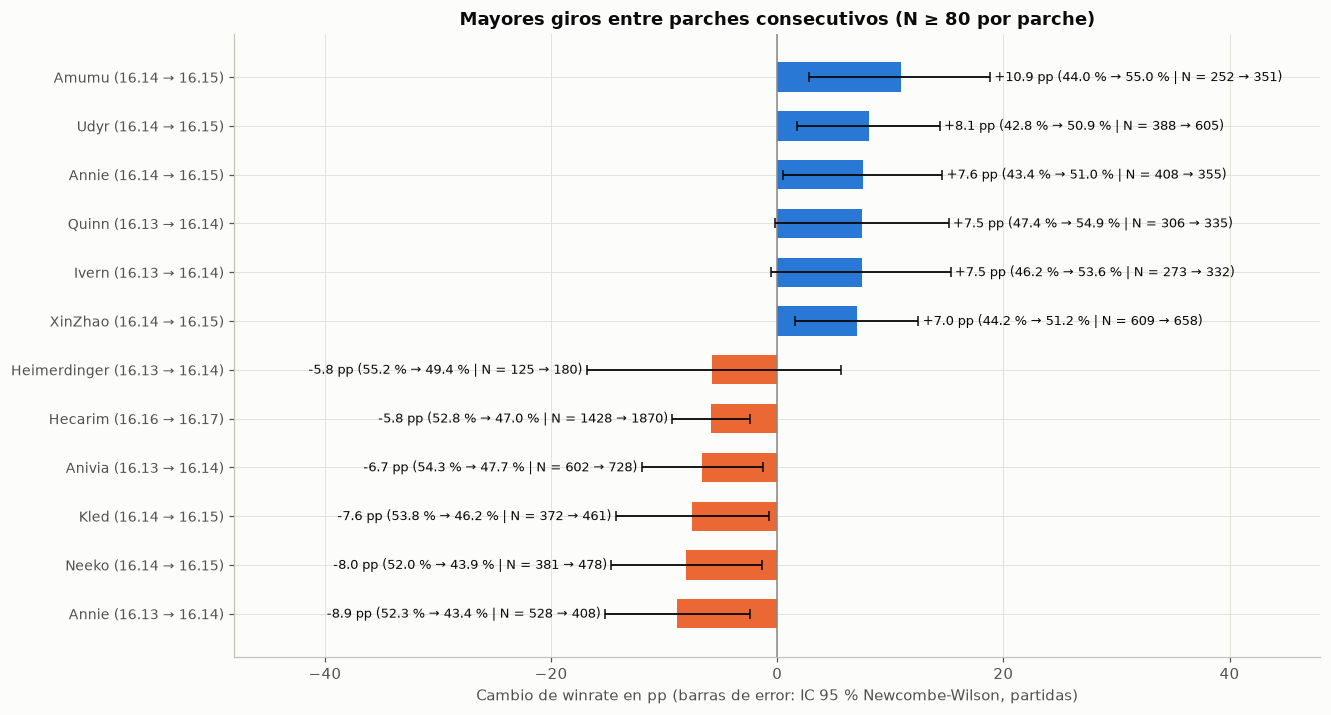

In [12]:
UMBRAL_PARCHE_META = 0.05
MIN_PATCH_GAMES = 80
MIN_TOTAL_GAMES = 400
FRAC_PARCHES_PRESENTE = 0.8
N_TRAYECTORIAS = 5
N_SALTOS = 6

share_parche = matches_train["patch"].astype(str).value_counts(normalize=True)
target_patches = sorted(share_parche[share_parche >= UMBRAL_PARCHE_META].index, key=patch_key)
min_presente = int(np.ceil(FRAC_PARCHES_PRESENTE * len(target_patches)))
print(f"Parches con ≥ {UMBRAL_PARCHE_META:.0%} de las partidas: {', '.join(target_patches)} "
      f"({share_parche[target_patches].sum():.1%} del train).")
print(f"Con {MIN_PATCH_GAMES} partidas, el IC 95 % de un winrate de 50 % es ± {100 * ic95(0.5, MIN_PATCH_GAMES):.1f} pp.")

cp_stats = (lane_rows[lane_rows["patch"].isin(target_patches)]
            .groupby(["champion_name", "patch"], observed=True)["win"].agg(games="size", wins="sum").reset_index())
cp_stats[["champion_name", "patch"]] = cp_stats[["champion_name", "patch"]].astype(str)
cp_stats["winrate"] = 100 * cp_stats["wins"] / cp_stats["games"]
p_wr = cp_stats.pivot(index="champion_name", columns="patch", values="winrate").reindex(columns=target_patches)
p_games = (cp_stats.pivot(index="champion_name", columns="patch", values="games")
           .reindex(columns=target_patches).fillna(0))

presentes = (p_games >= MIN_PATCH_GAMES).sum(axis=1)
valid_champs = p_games.index[(p_games.sum(axis=1) >= MIN_TOTAL_GAMES) & (presentes >= min_presente)]
masked_wr = p_wr.loc[valid_champs].where(p_games.loc[valid_champs] >= MIN_PATCH_GAMES)
wr_shifts = (masked_wr.max(axis=1) - masked_wr.min(axis=1)).sort_values(ascending=False)
top_champs = wr_shifts.head(N_TRAYECTORIAS).index
print(f"{len(valid_champs)} campeones cumplen el filtro.")

fig, ax = plt.subplots(figsize=(12.2, 6.2))
lo_all, hi_all = [], []
for i, champ in enumerate(top_champs):
    wrs = masked_wr.loc[champ].to_numpy(float)
    ns = p_games.loc[champ, target_patches].to_numpy(float)
    ok_p = np.isfinite(wrs) & (ns > 0)
    lo_c, hi_c = np.full_like(wrs, np.nan), np.full_like(wrs, np.nan)
    lo_w, hi_w = wilson_ci(wrs[ok_p] / 100.0, ns[ok_p])
    lo_c[ok_p], hi_c[ok_p] = 100.0 * lo_w, 100.0 * hi_w
    lo_all.append(lo_c[ok_p]); hi_all.append(hi_c[ok_p])
    ax.plot(target_patches, wrs, marker="o", linewidth=2, markersize=7, color=CATEGORICAL[i],
            label=f"{champ} (Δ {wr_shifts[champ]:.1f} pp, N = {int(p_games.loc[champ].sum()):,})")
    ax.fill_between(target_patches, lo_c, hi_c, color=CATEGORICAL[i], alpha=0.13)
ax.set_ylim(min(float(np.min(np.concatenate(lo_all))), 50) - 2, max(float(np.max(np.concatenate(hi_all))), 50) + 2)
ax.axhline(50, color=MUTED, linestyle="--", linewidth=1)
ax.set_title(f"Campeones con mayor giro de winrate entre parches (N ≥ {MIN_PATCH_GAMES} por parche)")
ax.set_xlabel("Parche")
ax.set_ylabel("Winrate % (bandas: IC 95 % Wilson por parche)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

trans = []
for p1, p2 in zip(target_patches[:-1], target_patches[1:]):
    ok = (p_games.loc[valid_champs, p1] >= MIN_PATCH_GAMES) & (p_games.loc[valid_champs, p2] >= MIN_PATCH_GAMES)
    for champ in valid_champs[ok.to_numpy()]:
        trans.append({"champion": champ, "transicion": f"{p1} → {p2}",
                      "delta": p_wr.loc[champ, p2] - p_wr.loc[champ, p1],
                      "wr1": p_wr.loc[champ, p1], "wr2": p_wr.loc[champ, p2],
                      "n1": int(p_games.loc[champ, p1]), "n2": int(p_games.loc[champ, p2])})
df_trans = pd.DataFrame(trans)
saltos = pd.concat([df_trans.nsmallest(N_SALTOS, "delta"), df_trans.nlargest(N_SALTOS, "delta")]).sort_values("delta")

# IC 95 % Newcombe-Wilson para diferencia de dos proporciones independientes (wr2 − wr1)
p1_s, p2_s = saltos["wr1"].to_numpy(float) / 100.0, saltos["wr2"].to_numpy(float) / 100.0
l1_s, u1_s = wilson_ci(p1_s, saltos["n1"].to_numpy(float))
l2_s, u2_s = wilson_ci(p2_s, saltos["n2"].to_numpy(float))
err_lo = 100.0 * np.sqrt((p2_s - l2_s) ** 2 + (u1_s - p1_s) ** 2)
err_hi = 100.0 * np.sqrt((u2_s - p2_s) ** 2 + (p1_s - l1_s) ** 2)

fig, ax = plt.subplots(figsize=(12.2, 6.6))
y = np.arange(len(saltos))
deltas = saltos["delta"].to_numpy()
ax.barh(y, deltas, color=np.where(deltas < 0, NEG, POS), height=0.6)
ax.errorbar(deltas, y, xerr=[err_lo, err_hi], fmt="none", ecolor=INK, elinewidth=1.2, capsize=3, zorder=5)
ext_max = float(np.max(np.maximum(np.abs(deltas - err_lo), np.abs(deltas + err_hi))))
margen = 0.02 * ext_max
for yi, row, el, eh in zip(y, saltos.itertuples(), err_lo, err_hi):
    txt = f"{row.delta:+.1f} pp ({row.wr1:.1f} % → {row.wr2:.1f} % | N = {row.n1} → {row.n2})"
    x_pos = (row.delta + eh + margen) if row.delta >= 0 else (row.delta - el - margen)
    ax.text(x_pos, yi, txt, va="center", ha="left" if row.delta >= 0 else "right", fontsize=8.3, color=INK)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_yticks(y, [f"{row.champion} ({row.transicion})" for row in saltos.itertuples()], fontsize=9)
ax.set_xlim(-2.55 * ext_max, 2.55 * ext_max)
ax.set_title(f"Mayores giros entre parches consecutivos (N ≥ {MIN_PATCH_GAMES} por parche)")
ax.set_xlabel("Cambio de winrate en pp (barras de error: IC 95 % Newcombe-Wilson, partidas)")
plt.tight_layout()
plt.show()

### 11. Cambio de winrate entre el primer y el último parche grande

Distribución de $\Delta WR = WR_{\text{último}} - WR_{\text{primero}}$ en puntos porcentuales,
entre el primer y el último de los parches de la sección 10. Entran los campeones con al menos
`MIN_PARTIDAS_EXTREMOS` partidas en ambos parches.

Para leerlo hay que comparar el desvío observado con el que produciría **solo el ruido
muestral** si ningún campeón hubiera cambiado: $\sqrt{\tfrac{p(1-p)}{n_1} + \tfrac{p(1-p)}{n_2}}$
con $p = 0{,}5$, promediado sobre los campeones. La celda imprime los dos. Si son parecidos,
la mayor parte de la dispersión no es meta.

173 campeones. Desvío observado: 2.66 pp; desvío esperado solo por ruido muestral: 2.53 pp.


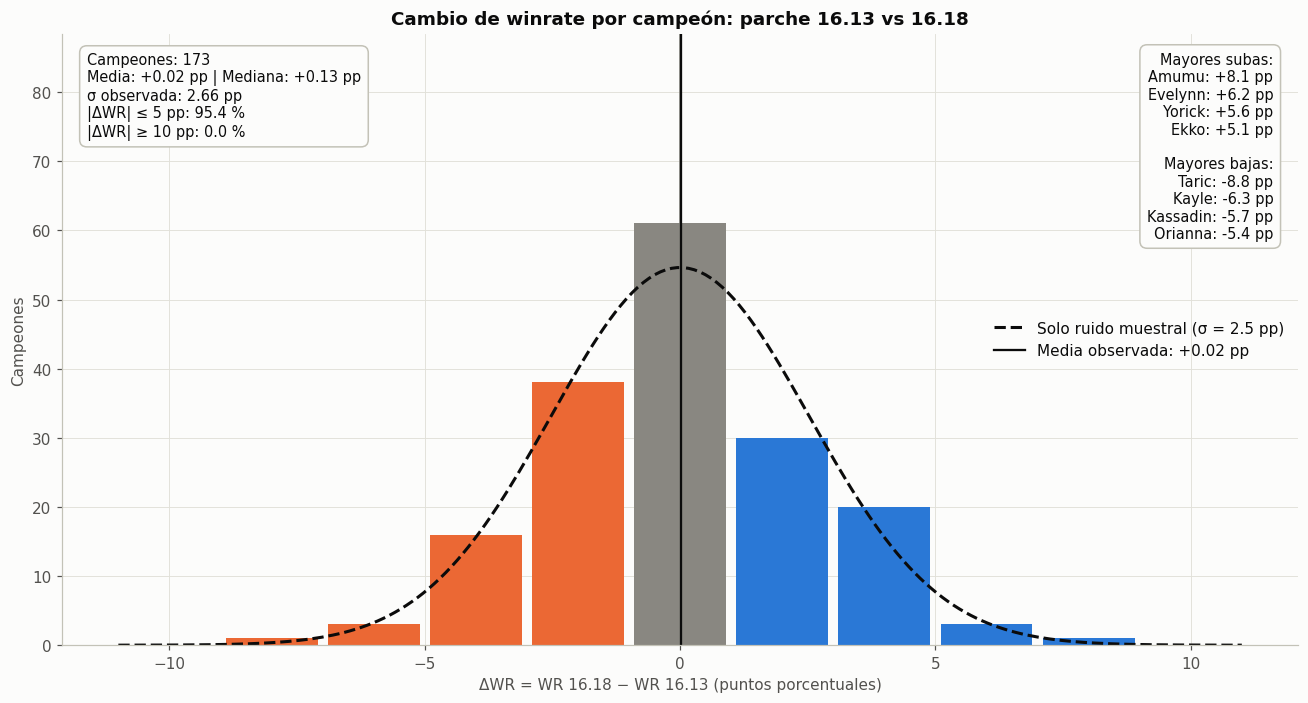

In [13]:
MIN_PARTIDAS_EXTREMOS = 40
ESTABLE_PP = 5
GIRO_PP = 10
BIN_PP = 2.0
N_DESTACADOS = 4

p_first, p_last = target_patches[0], target_patches[-1]
ext = p_games[[p_first, p_last]]
valid = ext.index[(ext[p_first] >= MIN_PARTIDAS_EXTREMOS) & (ext[p_last] >= MIN_PARTIDAS_EXTREMOS)]
delta_wr = (p_wr.loc[valid, p_last] - p_wr.loc[valid, p_first]).dropna()
sd_ruido = 100 * np.sqrt((0.25 / ext.loc[delta_wr.index, p_first] + 0.25 / ext.loc[delta_wr.index, p_last]).mean())
print(f"{len(delta_wr)} campeones. Desvío observado: {delta_wr.std():.2f} pp; "
      f"desvío esperado solo por ruido muestral: {sd_ruido:.2f} pp.")

# Bins centrados en múltiplos de BIN_PP, así el bin gris es |ΔWR| < BIN_PP / 2
k = int(np.ceil((delta_wr.abs().max() + BIN_PP / 2) / BIN_PP))
bins = np.arange(-k, k + 1) * BIN_PP + BIN_PP / 2
bins = np.concatenate([[bins[0] - BIN_PP], bins])
counts, edges = np.histogram(delta_wr, bins=bins)
centros = edges[:-1] + BIN_PP / 2
colores = np.where(np.isclose(centros, 0), MUTED, np.where(centros < 0, NEG, POS))

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.bar(centros, counts, width=BIN_PP * 0.9, color=colores)
xs = np.linspace(bins[0], bins[-1], 200)
ax.plot(xs, len(delta_wr) * BIN_PP * np.exp(-xs ** 2 / (2 * sd_ruido ** 2)) / (sd_ruido * np.sqrt(2 * np.pi)),
        color=INK, linewidth=2, linestyle="--", label=f"Solo ruido muestral (σ = {sd_ruido:.1f} pp)")
ax.axvline(0, color=MUTED, linewidth=1)
ax.axvline(delta_wr.mean(), color=INK, linewidth=1.5, label=f"Media observada: {delta_wr.mean():+.2f} pp")
estables = 100 * (delta_wr.abs() <= ESTABLE_PP).mean()
giros = 100 * (delta_wr.abs() >= GIRO_PP).mean()
ax.text(0.02, 0.97,
        f"Campeones: {len(delta_wr)}\nMedia: {delta_wr.mean():+.2f} pp | Mediana: {delta_wr.median():+.2f} pp\n"
        f"σ observada: {delta_wr.std():.2f} pp\n|ΔWR| ≤ {ESTABLE_PP} pp: {estables:.1f} %\n|ΔWR| ≥ {GIRO_PP} pp: {giros:.1f} %",
        transform=ax.transAxes, va="top", fontsize=9.5, color=INK,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#fcfcfb", edgecolor="#c3c2b7"))
destacados = ("Mayores subas:\n" + "\n".join(f"{c}: {d:+.1f} pp" for c, d in delta_wr.nlargest(N_DESTACADOS).items())
              + "\n\nMayores bajas:\n" + "\n".join(f"{c}: {d:+.1f} pp" for c, d in delta_wr.nsmallest(N_DESTACADOS).items()))
ax.text(0.98, 0.97, destacados, transform=ax.transAxes, va="top", ha="right", fontsize=9.5, color=INK,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="#fcfcfb", edgecolor="#c3c2b7"))
ax.set_ylim(0, counts.max() * 1.45)
ax.set_title(f"Cambio de winrate por campeón: parche {p_first} vs {p_last}")
ax.set_xlabel(f"ΔWR = WR {p_last} − WR {p_first} (puntos porcentuales)")
ax.set_ylabel("Campeones")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

## Parte C. Jugadores y estilo

Como la Parte B, solo con el train.

### 12. Diversidad de roles y de campeones por jugador

Para los jugadores con al menos `MIN_GAMES_DIV` partidas en las 5 posiciones: cuántos roles y
cuántos campeones superan `UMBRAL_SIG` de sus partidas. El umbral filtra los autofill y los
campeones que se jugaron pocas veces.

Debajo, el reparto promedio de partidas por rol: para cada jugador se ordenan sus 5 roles de
más a menos jugado (1.º = rol principal) y se promedia, entre jugadores, la proporción y la
cantidad de partidas en cada puesto del ranking. Así se ve cuánto pesa el main frente al
secundario sin depender de un umbral.

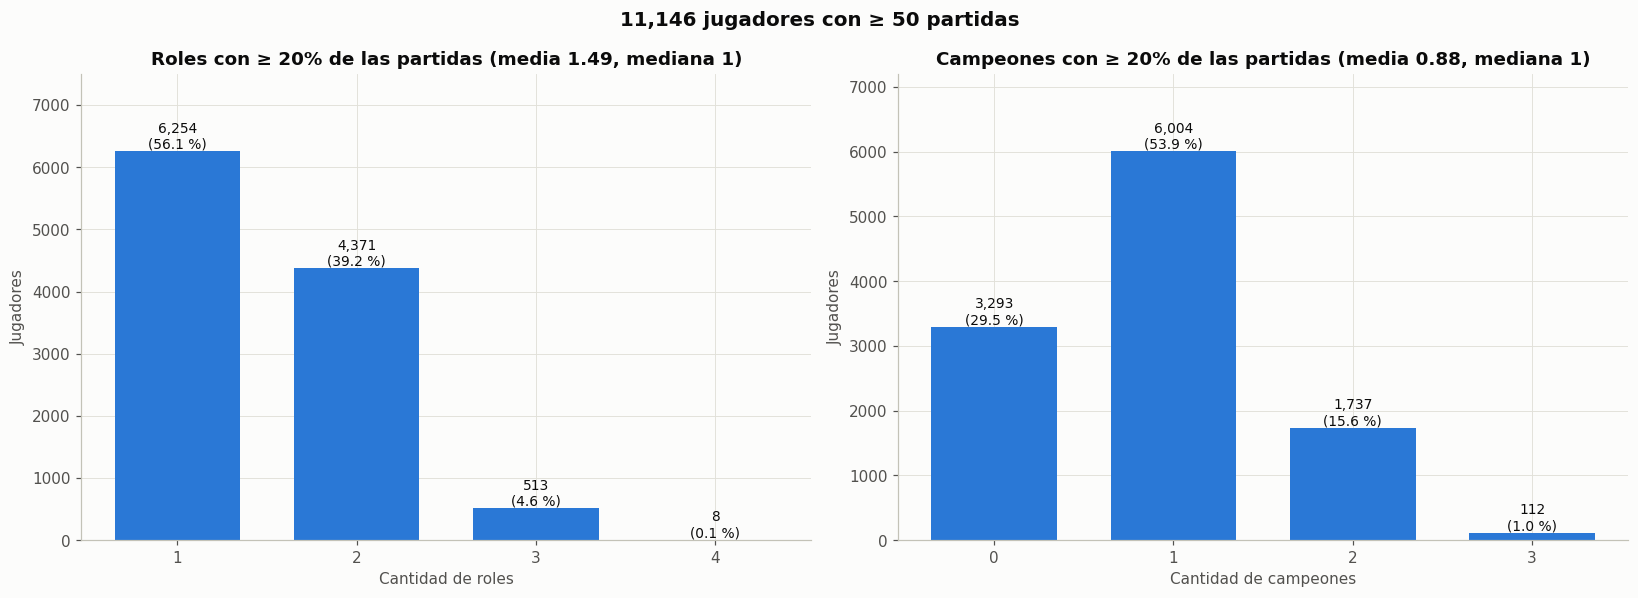

In [14]:
MIN_GAMES_DIV = 50
UMBRAL_SIG = 0.20

n_por_jugador = lane_rows.groupby("player_id").size()
objetivo = lane_rows[lane_rows["player_id"].isin(n_por_jugador[n_por_jugador >= MIN_GAMES_DIV].index)]


def n_significativos(col):
    cuenta = objetivo.groupby(["player_id", col], observed=True).size()
    share = cuenta / cuenta.groupby(level=0).transform("sum")
    return (share >= UMBRAL_SIG).groupby(level=0).sum()


fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (col, nombre) in zip(axes, [("lane", "roles"), ("champion_name", "campeones")]):
    serie = n_significativos(col)
    dist = serie.value_counts().sort_index()
    ax.bar(dist.index, dist.to_numpy(), color=CATEGORICAL[0], width=0.7)
    for k, v in dist.items():
        ax.text(k, v, f"{v:,}\n({100 * v / len(serie):.1f} %)", ha="center", va="bottom", fontsize=9, color=INK)
    ax.set_xticks(dist.index)
    ax.set_ylim(0, dist.max() * 1.2)
    ax.set_title(f"{nombre.capitalize()} con ≥ {UMBRAL_SIG:.0%} de las partidas "
                 f"(media {serie.mean():.2f}, mediana {serie.median():.0f})")
    ax.set_xlabel(f"Cantidad de {nombre}")
    ax.set_ylabel("Jugadores")
plt.suptitle(f"{len(serie):,} jugadores con ≥ {MIN_GAMES_DIV} partidas", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

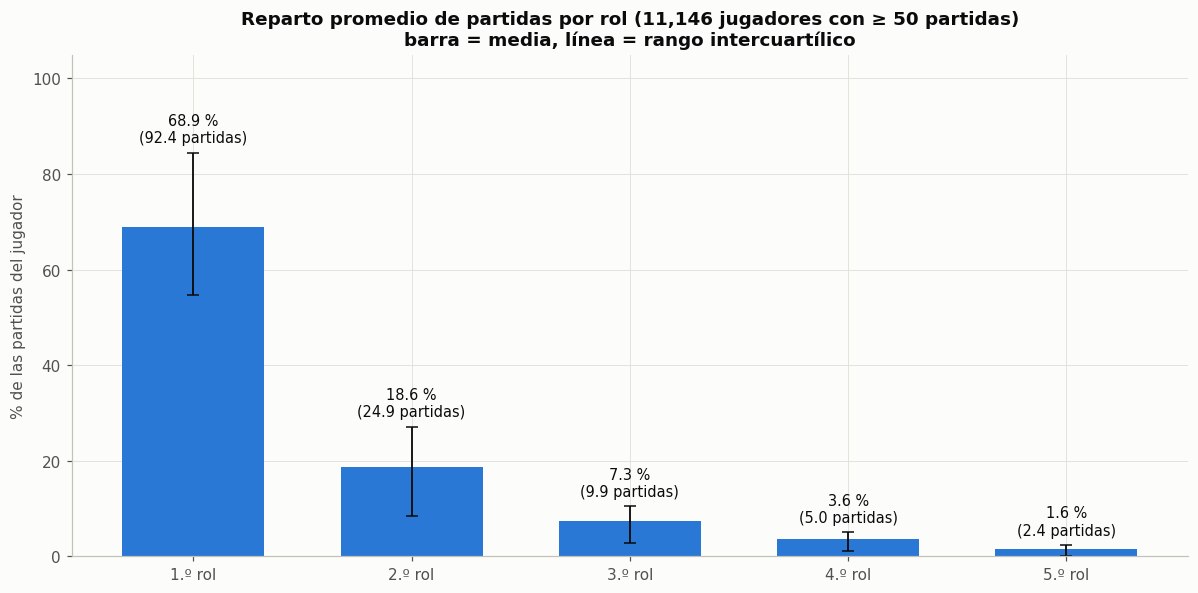

,% medio,% mediana,partidas medias
1.º rol,68.9,69.9,92.4
2.º rol,18.6,17.6,24.9
3.º rol,7.3,5.6,9.9
4.º rol,3.6,2.7,5.0
5.º rol,1.6,1.1,2.4


In [15]:
# Reparto de partidas por rol, ordenado de más a menos jugado por cada jugador
cuenta_rol = (objetivo.groupby(["player_id", "lane"], observed=True).size()
              .unstack(fill_value=0).reindex(columns=LANES, fill_value=0))
partidas_rank = pd.DataFrame(-np.sort(-cuenta_rol.to_numpy(), axis=1), index=cuenta_rol.index,
                             columns=[f"{k}.º rol" for k in range(1, len(LANES) + 1)])
share_rank = 100 * partidas_rank.div(partidas_rank.sum(axis=1), axis=0)

media = share_rank.mean()
q1, q3 = share_rank.quantile(0.25), share_rank.quantile(0.75)
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(media))
ax.bar(x, media, color=CATEGORICAL[0], width=0.65)
ax.errorbar(x, media, yerr=[media - q1, q3 - media], fmt="none", ecolor=INK, capsize=4, linewidth=1.2)
for k, col in enumerate(media.index):
    ax.text(k, q3[col] + 1.5, f"{media[col]:.1f} %\n({partidas_rank[col].mean():.1f} partidas)",
            ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(x, media.index)
ax.set_ylim(0, 105)
ax.set_ylabel("% de las partidas del jugador")
ax.set_title(f"Reparto promedio de partidas por rol ({len(share_rank):,} jugadores con ≥ {MIN_GAMES_DIV} partidas)\n"
             "barra = media, línea = rango intercuartílico")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"% medio": media, "% mediana": share_rank.median(),
                      "partidas medias": partidas_rank.mean()}).round(1))

### 13. Timeline por rol (@10, @15, @20)

Mediana de oro, farm, experiencia y daño a campeones en cada minuto, por posición. El nivel
depende mucho del rol, así que un promedio general mezclaría poblaciones distintas. En `@20`
solo quedan las partidas que llegaron al minuto 20 (sección 2).

Las barras son el **intervalo de confianza del 95 % de la mediana**, no la dispersión entre
partidas. Con cientos de miles de filas por rol quedan más chicas que el marcador: la mediana
de cada rol está medida con mucha precisión. La dispersión entre partidas es otra cosa: en daño
es amplia (P25–P75 de alrededor de ±25 % de la mediana) porque depende mucho del campeón
(sección 16), no por un error en los datos: a los 20 minutos coincide con el daño final de las
partidas que terminan en ese minuto.

El IC de la mediana sale de los estadísticos de orden: con $n$ observaciones, la mediana
verdadera queda entre los cuantiles $\tfrac12 \pm 1{,}96\,\tfrac{\sqrt{n}}{2n}$ con un 95 % de
confianza (aproximación normal a la binomial), sin suponer normalidad de la variable.

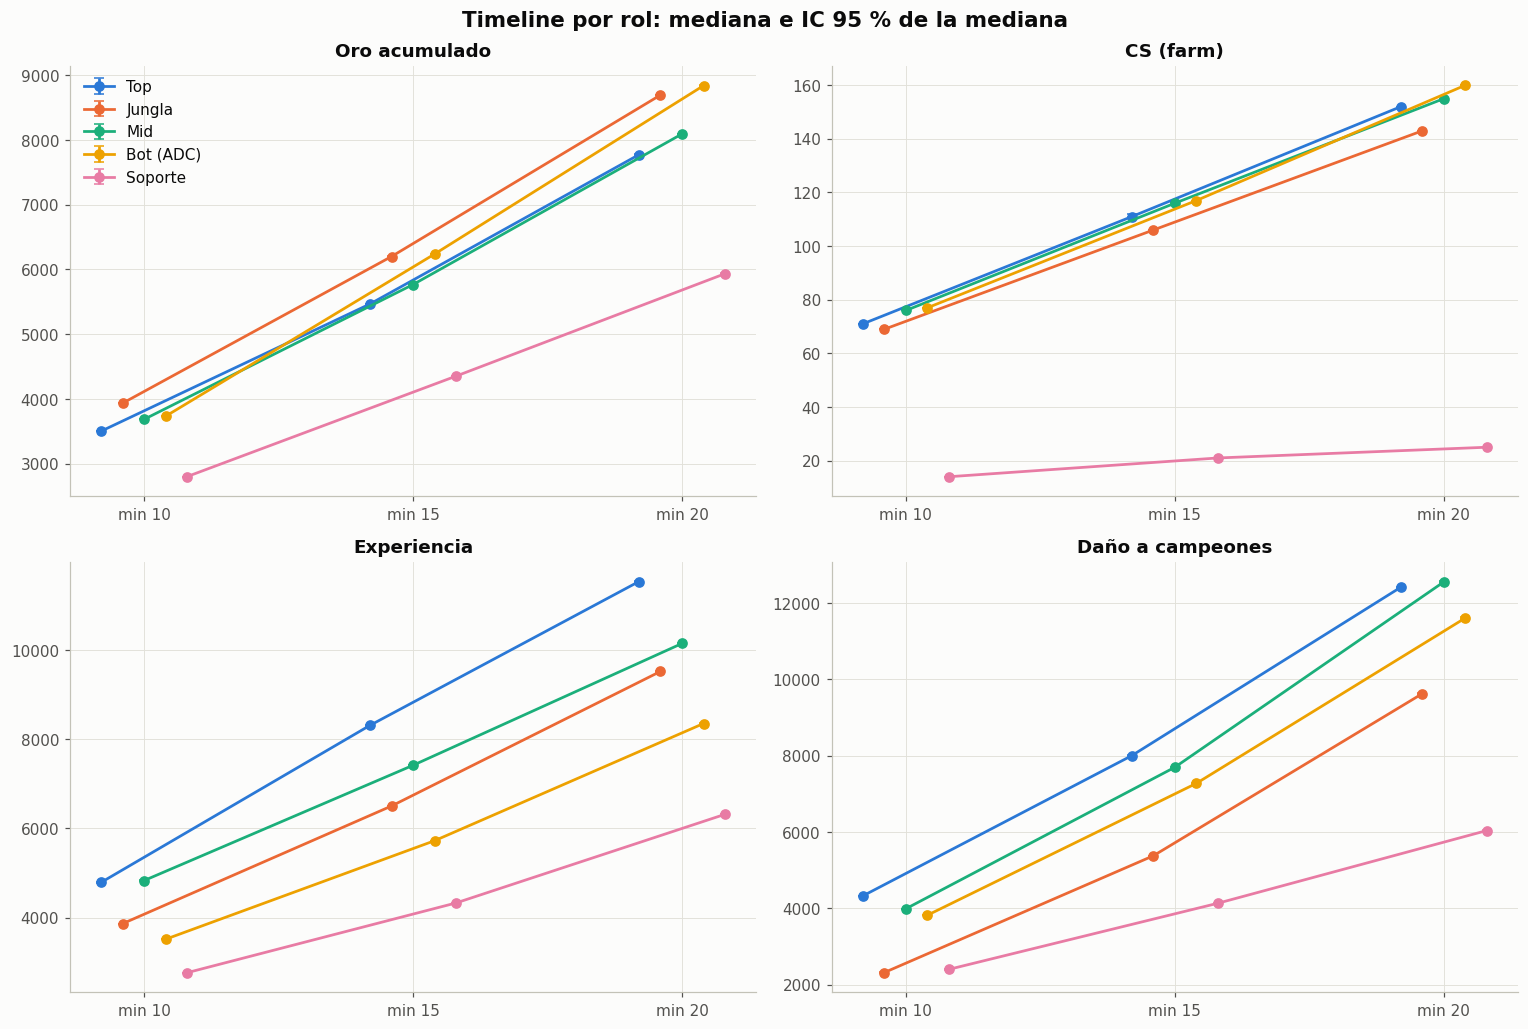

In [16]:
MINUTOS = [10, 15, 20]
VARS_TL = {"gold": "Oro acumulado", "cs": "CS (farm)", "xp": "Experiencia", "damage": "Daño a campeones"}
DESPLAZAMIENTO = 0.08  # separación horizontal entre roles en cada minuto
Z_95 = 1.96


def resumen_mediana(s):
    """Mediana, su IC 95 % por estadísticos de orden, P25 y P75 de una serie."""
    s = s.dropna()
    h = Z_95 * 0.5 / np.sqrt(len(s))
    lo, q1, med, q3, hi = s.quantile([0.5 - h, 0.25, 0.5, 0.75, 0.5 + h]).to_numpy()
    return dict(med=med, lo=lo, hi=hi, q1=q1, q3=q3, n=len(s))


fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
for ax, (v, nombre) in zip(axes.flat, VARS_TL.items()):
    for k, lane in enumerate(LANES):
        en_linea = lane_rows.loc[lane_rows["lane"] == lane]
        r = [resumen_mediana(en_linea[f"{v}_{t}"]) for t in MINUTOS]
        med, lo, hi = (np.array([x[c] for x in r]) for c in ("med", "lo", "hi"))
        x = np.arange(len(MINUTOS)) + (k - (len(LANES) - 1) / 2) * DESPLAZAMIENTO
        ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt="o-", color=LANE_COLORS[lane], markersize=6,
                    linewidth=1.8, capsize=3, label=LANE_NAMES[lane])
    ax.set_xticks(range(len(MINUTOS)), [f"min {t}" for t in MINUTOS])
    ax.set_title(nombre)
axes[0, 0].legend(loc="upper left")
plt.suptitle("Timeline por rol: mediana e IC 95 % de la mediana", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### 14. Diferencia contra el rival de línea, desde el lado ganador

Para cada enfrentamiento de línea (`matchups_1v1.csv`), la diferencia de oro, CS y
experiencia en el minuto `t`, **medida desde el jugador del equipo que ganó la partida**.
Mostrar también a los perdedores no agrega nada, porque su distribución es exactamente la
misma con el signo invertido. Si la mediana está por encima de 0, el equipo ganador suele ir
adelante en esa línea a ese minuto.

Como en la sección 13, las barras son el IC 95 % de la mediana. La dispersión entre partidas
es enorme comparada con la mediana (el P25 es negativo en casi todas las líneas y minutos): ir
adelante en la línea se asocia con ganar, pero en una partida concreta decide poco.

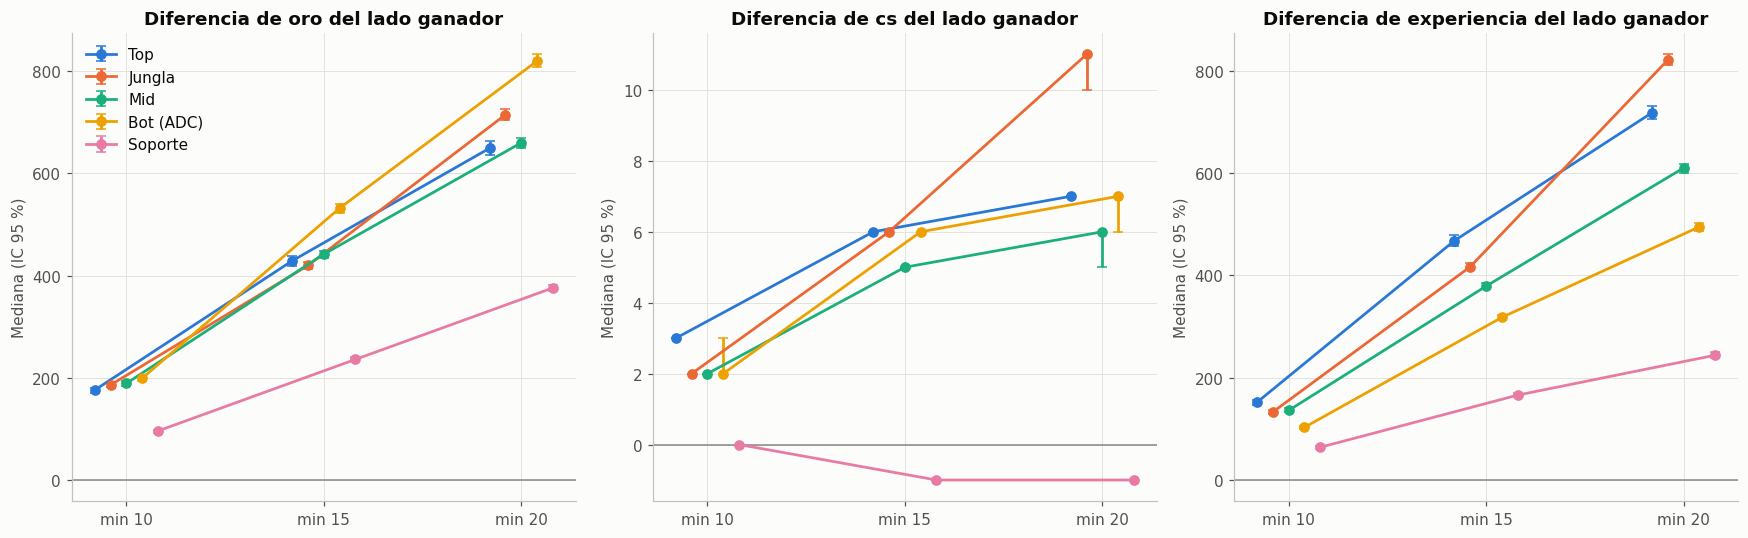

In [17]:
VARS_DIFF = {"gold": "Oro", "cs": "CS", "xp": "Experiencia"}

mu = df_matchups[df_matchups["lane"].isin(LANES)]
signo = np.where(mu["blue_win"].astype(int) == 1, 1, -1)

fig, axes = plt.subplots(1, len(VARS_DIFF), figsize=(16, 5))
for ax, (v, nombre) in zip(axes, VARS_DIFF.items()):
    for k, lane in enumerate(LANES):
        en_linea = (mu["lane"] == lane).to_numpy()
        r = []
        for t in MINUTOS:
            d = pd.Series(signo[en_linea] * mu.loc[en_linea, f"diff_{v}_{t}"].to_numpy()).dropna()
            r.append(resumen_mediana(d))
        med, lo, hi = (np.array([x[c] for x in r]) for c in ("med", "lo", "hi"))
        x = np.arange(len(MINUTOS)) + (k - (len(LANES) - 1) / 2) * DESPLAZAMIENTO
        ax.errorbar(x, med, yerr=[med - lo, hi - med], fmt="o-", color=LANE_COLORS[lane], markersize=6,
                    linewidth=1.8, capsize=3, label=LANE_NAMES[lane])
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xticks(range(len(MINUTOS)), [f"min {t}" for t in MINUTOS])
    ax.set_title(f"Diferencia de {nombre.lower()} del lado ganador")
    ax.set_ylabel("Mediana (IC 95 %)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

### 15. Perfiles de jugador por rol principal

Distribución de cuatro variables de estilo de `players.csv` para los jugadores con al menos
`MIN_PARTIDAS_PERFIL` partidas, separados por su rol principal (`main_lane`). La caja es el
rango intercuartílico, la línea es la mediana y los bigotes llegan a 1,5 veces el IQR (sin
outliers dibujados). Como cada variable es un promedio del jugador, con pocas partidas es
ruidosa. El mínimo de partidas filtra a los jugadores con muy pocas observaciones.

22,907 jugadores con ≥ 10 partidas. Por rol principal: {'Top': 4279, 'Jungla': 4593, 'Mid': 5195, 'Bot (ADC)': 4567, 'Soporte': 4273}


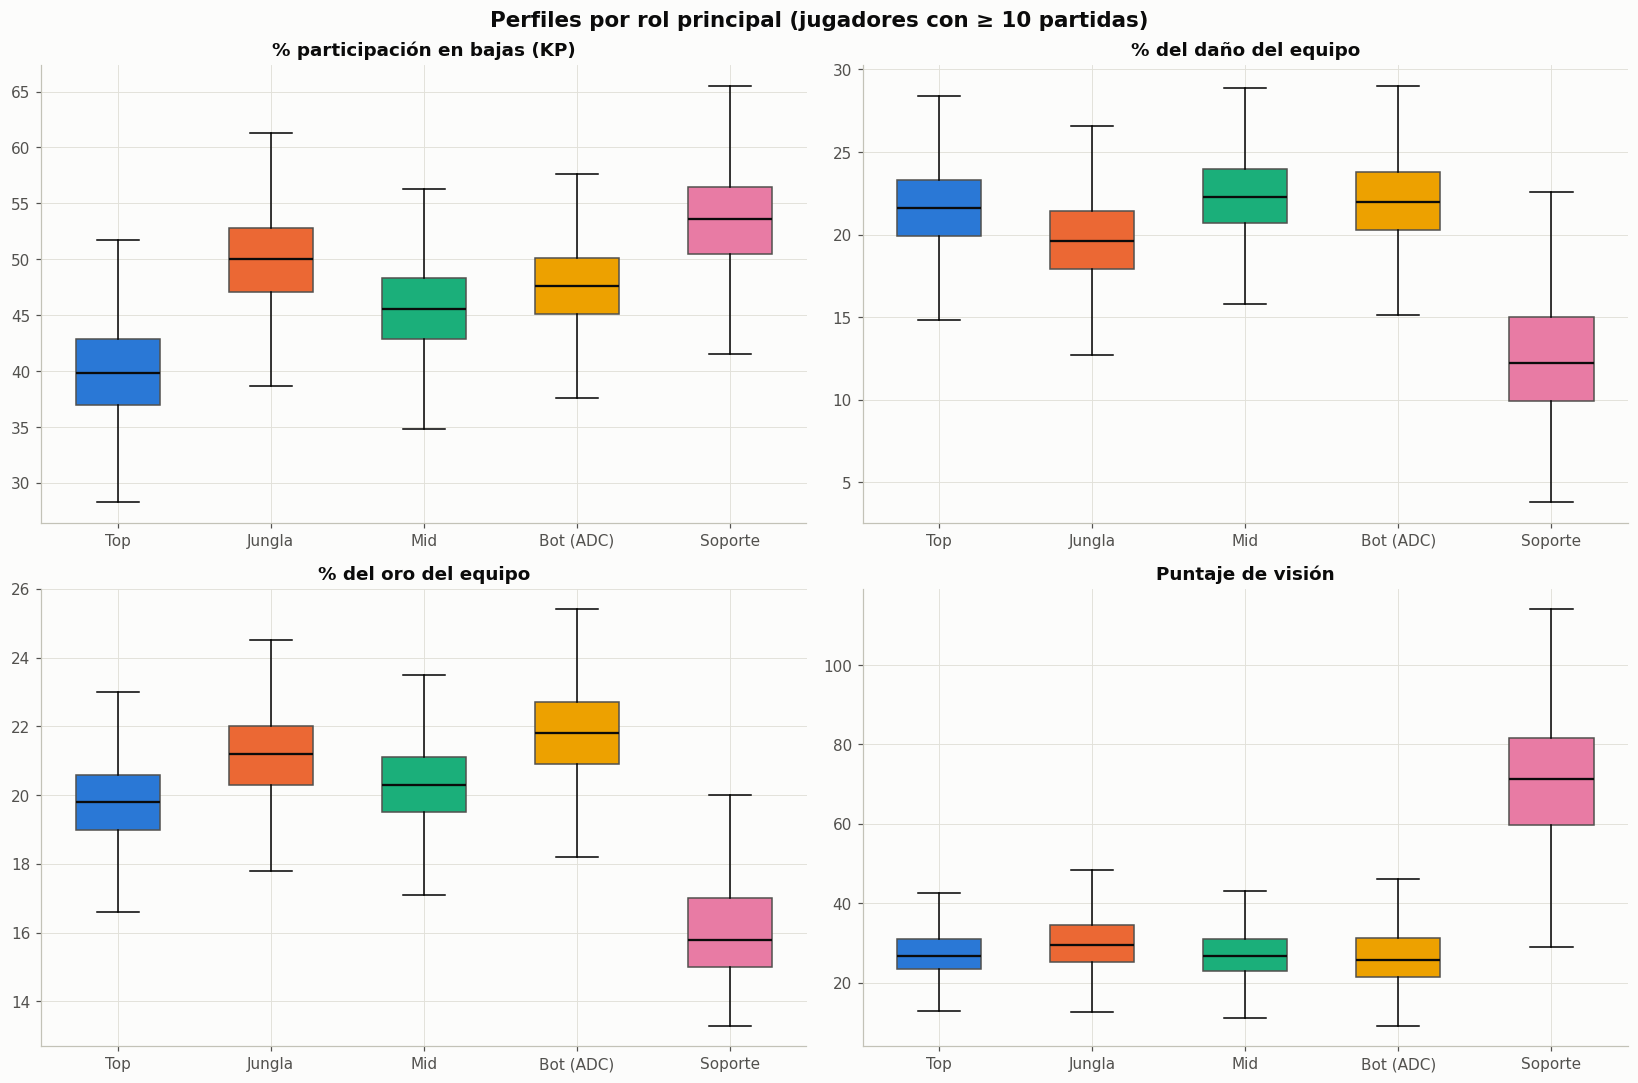

,% participación en bajas (KP),% del daño del equipo,% del oro del equipo,Puntaje de visión
main_lane,,,,
Top,39.8,21.6,19.8,26.8
Jungla,50.0,19.6,21.2,29.6
Mid,45.6,22.3,20.3,26.6
Bot (ADC),47.6,22.0,21.8,25.6
Soporte,53.6,12.2,15.8,71.4


In [18]:
MIN_PARTIDAS_PERFIL = 10
VARS_PERFIL = {
    "avg_kill_participation_pct": "% participación en bajas (KP)",
    "avg_damage_share_pct": "% del daño del equipo",
    "avg_gold_share_pct": "% del oro del equipo",
    "avg_vision_score": "Puntaje de visión",
}

perf = df_players[(df_players["games_recorded"] >= MIN_PARTIDAS_PERFIL) & df_players["main_lane"].isin(LANES)]
print(f"{len(perf):,} jugadores con ≥ {MIN_PARTIDAS_PERFIL} partidas. Por rol principal:",
      perf["main_lane"].value_counts().reindex(LANES).rename(LANE_NAMES).to_dict())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (col, nombre) in zip(axes.flat, VARS_PERFIL.items()):
    datos = [perf.loc[perf["main_lane"] == lane, col].dropna() for lane in LANES]
    caja = ax.boxplot(datos, patch_artist=True, showfliers=False, widths=0.55,
                      medianprops=dict(color=INK, linewidth=1.5))
    for patch, lane in zip(caja["boxes"], LANES):
        patch.set_facecolor(LANE_COLORS[lane])
        patch.set_edgecolor(INK_2)
    ax.set_xticks(range(1, len(LANES) + 1), [LANE_NAMES[l] for l in LANES])
    ax.set_title(nombre)
plt.suptitle(f"Perfiles por rol principal (jugadores con ≥ {MIN_PARTIDAS_PERFIL} partidas)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
display(perf.groupby("main_lane")[list(VARS_PERFIL)].median().reindex(LANES)
        .rename(index=LANE_NAMES, columns=VARS_PERFIL).round(1))

### 16. Cuánto explican el rol y el campeón

Para cada variable por partida, la fracción de su varianza que explica la posición y la que
explica la combinación posición + campeón:

$$\eta^2 = \frac{\sum_g n_g(\bar y_g - \bar y)^2}{\sum_i (y_i - \bar y)^2}$$

Un $\eta^2$ alto en rol significa que la variable describe **qué rol se jugó** más que **cómo
jugó la persona**. Antes de comparar jugadores con esa variable hay que normalizarla por rol
(o por rol y campeón). El $\eta^2$ con muchos grupos se infla un poco, pero con millones de
filas el efecto es despreciable.

La tabla se ordena por el **aporte del campeón** (η² de rol + campeón menos η² de rol), de mayor a menor: arriba quedan las variables en las que el campeón cambia más el resultado que el rol solo.

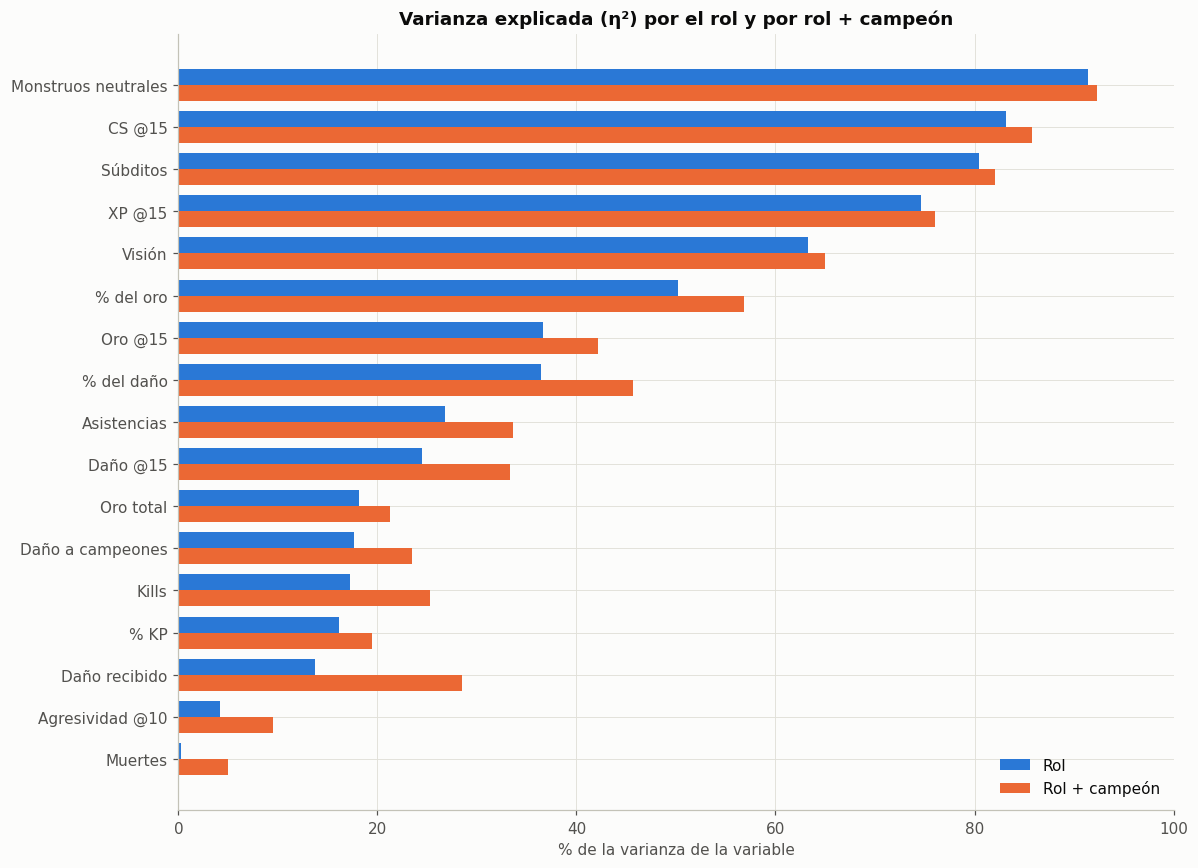

,rol,rol + campeón,aporte del campeón
Daño recibido,13.7,28.5,14.8
% del daño,36.4,45.6,9.2
Daño @15,24.5,33.4,8.8
Kills,17.2,25.3,8.1
Asistencias,26.8,33.6,6.8
% del oro,50.2,56.9,6.7
Daño a campeones,17.6,23.5,5.9
Oro @15,36.7,42.2,5.5
Agresividad @10,4.2,9.5,5.3
Muertes,0.3,5.0,4.7


In [19]:
FEATURES_NUM = {
    "kills": "Kills", "deaths": "Muertes", "assists": "Asistencias",
    "kill_participation_pct": "% KP", "damage_share_pct": "% del daño", "gold_share_pct": "% del oro",
    "total_damage_dealt_to_champions": "Daño a campeones", "total_damage_taken": "Daño recibido",
    "gold_earned": "Oro total", "total_minions_killed": "Súbditos", "neutral_minions_killed": "Monstruos neutrales",
    "vision_score": "Visión", "early_aggression_10": "Agresividad @10",
    "cs_15": "CS @15", "gold_15": "Oro @15", "xp_15": "XP @15", "damage_15": "Daño @15",
}


def eta2(y, grupos):
    ok = y.notna()
    y = y[ok]
    ajuste = y.groupby([g[ok] for g in grupos], observed=True).transform("mean")
    return ajuste.var() / y.var()


tabla_eta = pd.DataFrame({
    "rol": {c: eta2(lane_rows[c], [lane_rows["lane"]]) for c in FEATURES_NUM},
    "rol + campeón": {c: eta2(lane_rows[c], [lane_rows["lane"], lane_rows["champion_name"]]) for c in FEATURES_NUM},
}).sort_values("rol")
tabla_eta.index = tabla_eta.index.map(FEATURES_NUM)

fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(tabla_eta))
alto = 0.38
ax.barh(y + alto / 2, 100 * tabla_eta["rol"], height=alto, color=CATEGORICAL[0], label="Rol")
ax.barh(y - alto / 2, 100 * tabla_eta["rol + campeón"], height=alto, color=CATEGORICAL[1], label="Rol + campeón")
ax.set_yticks(y, tabla_eta.index)
ax.set_xlim(0, 100)
ax.set_title("Varianza explicada (η²) por el rol y por rol + campeón")
ax.set_xlabel("% de la varianza de la variable")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
tabla_pct = 100 * tabla_eta.astype(float)
tabla_pct["aporte del campeón"] = tabla_pct["rol + campeón"] - tabla_pct["rol"]
display(tabla_pct.sort_values("aporte del campeón", ascending=False).round(1))

### 17. Correlaciones y redundancia entre variables

Correlación de Spearman entre las variables por partida, **calculada dentro de cada rol**: cada
variable se pasa a percentil dentro de su posición antes de correlacionar. Sin ese paso, el rol
fabrica correlaciones. Por ejemplo, oro y daño aparecerían correlacionados solo porque el ADC
tiene mucho de los dos y el soporte poco. Los pares con $|\rho| \ge$ `UMBRAL_REDUNDANCIA` miden
casi lo mismo y conviene quedarse con uno solo. Se usa una muestra aleatoria de filas.

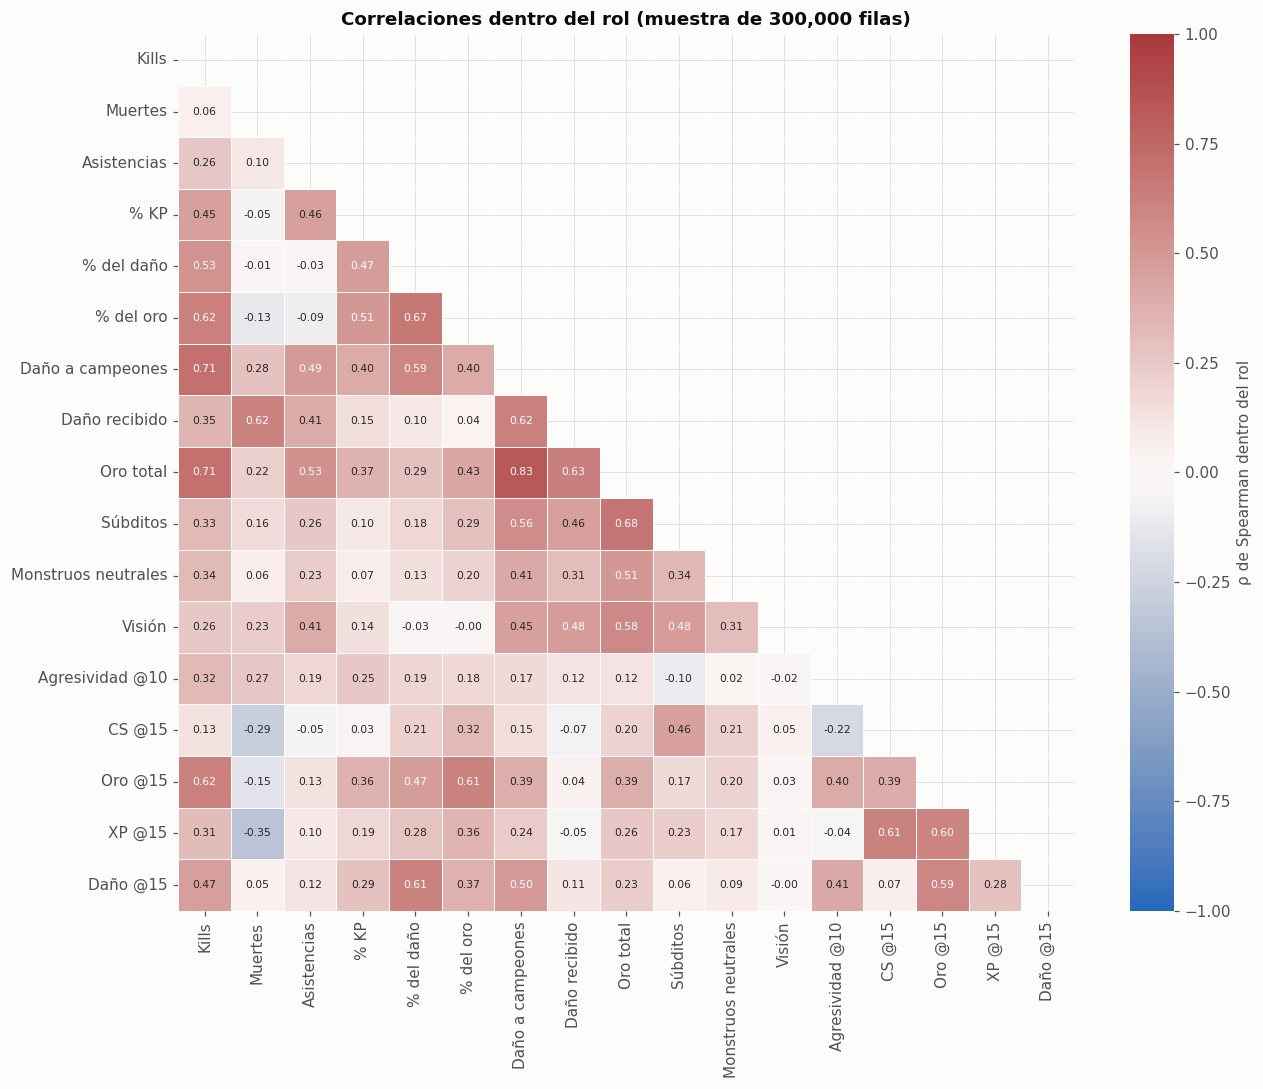

Pares con |ρ| ≥ 0.8 dentro del rol: 1 (sin separar por rol serían 1).


,,ρ
Daño a campeones,Oro total,0.829


In [20]:
MUESTRA_CORR = 300_000
SEED = 42
UMBRAL_REDUNDANCIA = 0.8

cols = list(FEATURES_NUM)
muestra = lane_rows[["lane"] + cols].sample(n=min(MUESTRA_CORR, len(lane_rows)), random_state=SEED)
corr_rol = muestra.groupby("lane", observed=True)[cols].rank(pct=True).corr()
corr_bruta = muestra[cols].rank(pct=True).corr()


def pares_altos(c):
    sup = c.where(np.triu(np.ones(c.shape, dtype=bool), k=1)).stack()
    return sup[sup.abs() >= UMBRAL_REDUNDANCIA].sort_values(key=abs, ascending=False)


etiquetas = [FEATURES_NUM[c] for c in cols]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_rol.set_axis(etiquetas).set_axis(etiquetas, axis=1), ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones(corr_rol.shape, dtype=bool)), annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"label": "ρ de Spearman dentro del rol"})
ax.set_title(f"Correlaciones dentro del rol (muestra de {len(muestra):,} filas)")
plt.tight_layout()
plt.show()

altos = pares_altos(corr_rol)
print(f"Pares con |ρ| ≥ {UMBRAL_REDUNDANCIA} dentro del rol: {len(altos)} "
      f"(sin separar por rol serían {len(pares_altos(corr_bruta))}).")
display(altos.rename(index=FEATURES_NUM).rename("ρ").round(3).to_frame())

### 18. Variables del jugador y su winrate

Correlación de Spearman entre los promedios de cada jugador (`players.csv`) y su winrate, para
los jugadores con al menos `MIN_PARTIDAS_CORR` partidas. Igual que en la sección 17, cada
variable se pasa a percentil **dentro del rol principal** del jugador antes de correlacionar:
si no, el rol fabrica correlaciones (un soporte tiene mucha visión y poco daño, sin que eso
diga nada de cómo juega).

Dos cuidados al leerla:

* **Ruido del winrate.** Con $n$ partidas, el winrate tiene un error estándar de
  $\sqrt{p(1-p)/n} \approx 0{,}5/\sqrt{n}$: con 50 partidas son 7 pp. Ese ruido atenúa
  todas las correlaciones con el winrate, así que los valores son una cota inferior.
* **Variables de resultado.** KDA, muertes, diferencias al final de la partida o el % de
  oro son en parte *consecuencia* de ganar, no causa. Que correlacionen con el winrate no
  las hace útiles para predecir una partida antes de jugarla. Las variables tempranas
  (`@10`, `@15`) y las de estilo (pool, foco de rol) son las que pueden usarse como
  descriptores previos del jugador.

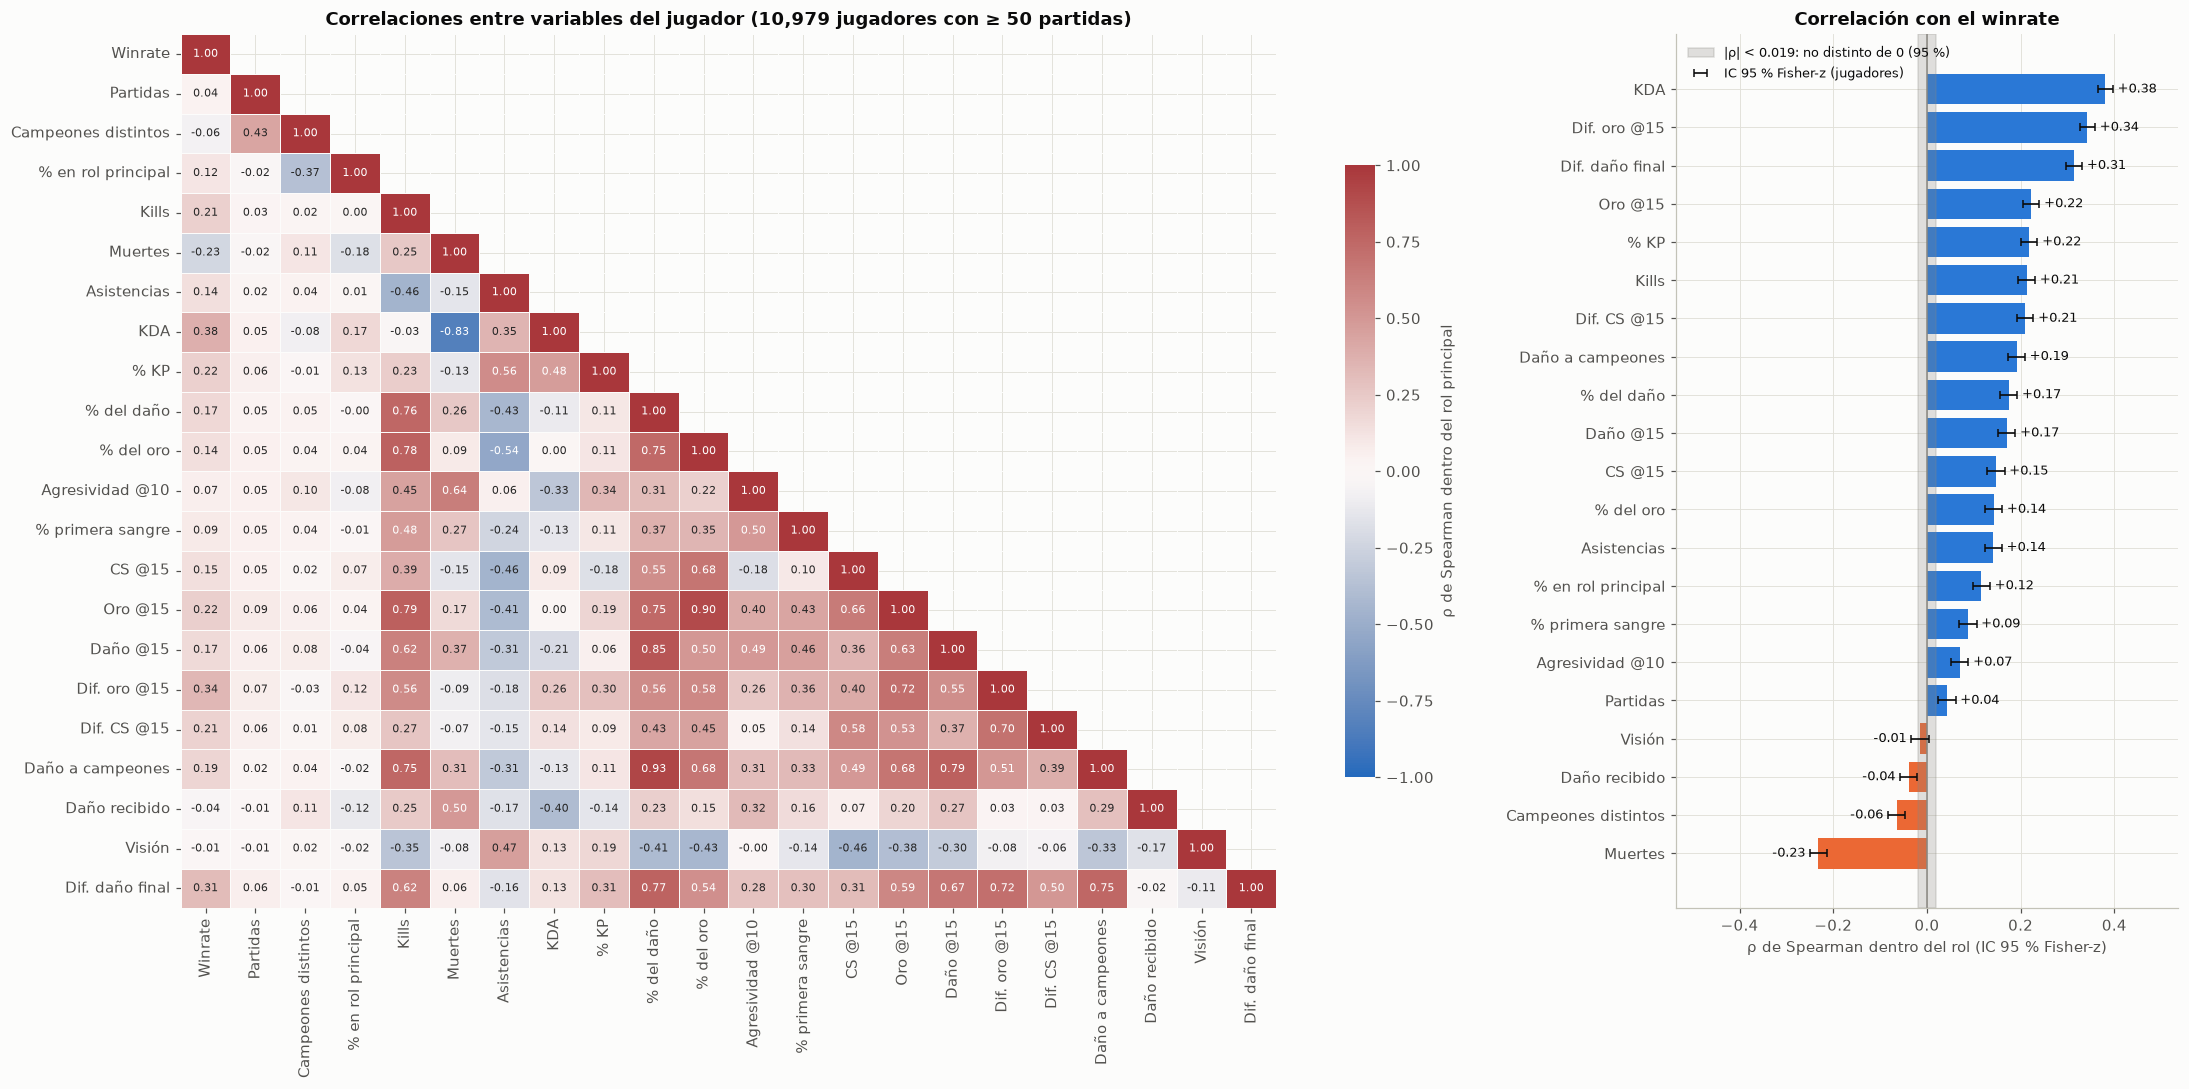

Error estándar del winrate con 50 partidas: ±7.1 pp; mediana de partidas en la muestra: 106.


,ρ con el winrate
KDA,0.381
Dif. oro @15,0.342
Dif. daño final,0.315
Oro @15,0.222
% KP,0.218
Kills,0.213
Dif. CS @15,0.210
Daño a campeones,0.191
% del daño,0.175
Daño @15,0.171


In [21]:
MIN_PARTIDAS_CORR = 50
VARS_JUGADOR = {
    "winrate_pct": "Winrate",
    "games_recorded": "Partidas",
    "unique_champions_count": "Campeones distintos",
    "role_focus_pct": "% en rol principal",
    "avg_kills": "Kills", "avg_deaths": "Muertes", "avg_assists": "Asistencias", "avg_kda": "KDA",
    "avg_kill_participation_pct": "% KP", "avg_damage_share_pct": "% del daño", "avg_gold_share_pct": "% del oro",
    "avg_early_aggression_10": "Agresividad @10", "first_blood_rate_pct": "% primera sangre",
    "avg_cs_at_15": "CS @15", "avg_gold_at_15": "Oro @15", "avg_damage_at_15": "Daño @15",
    "avg_gold_diff_at_15": "Dif. oro @15", "avg_cs_diff_at_15": "Dif. CS @15",
    "avg_total_damage": "Daño a campeones", "avg_damage_taken": "Daño recibido",
    "avg_vision_score": "Visión", "avg_damage_diff_end": "Dif. daño final",
}

jug = df_players[(df_players["games_recorded"] >= MIN_PARTIDAS_CORR) & df_players["main_lane"].isin(LANES)]
cols_j = list(VARS_JUGADOR)
rangos = jug.groupby("main_lane")[cols_j].rank(pct=True)
corr_jug = rangos.corr(method="pearson").rename(index=VARS_JUGADOR, columns=VARS_JUGADOR)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10), gridspec_kw={"width_ratios": [3, 1.1]})
sns.heatmap(corr_jug, ax=ax1, cmap="vlag", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones(corr_jug.shape, dtype=bool), k=1), annot=True, fmt=".2f",
            annot_kws={"fontsize": 7}, linewidths=0.5, linecolor="#fcfcfb",
            cbar_kws={"label": "ρ de Spearman dentro del rol principal", "shrink": 0.7})
ax1.set_title(f"Correlaciones entre variables del jugador ({len(jug):,} jugadores con ≥ {MIN_PARTIDAS_CORR} partidas)")

# Transformación de Fisher: IC 95 % de cada ρ y banda de significancia frente a 0
con_wr = corr_jug["Winrate"].drop("Winrate").sort_values()
ic = Z_95 / np.sqrt(len(jug) - 3)
z_r = np.arctanh(np.clip(con_wr.to_numpy(float), -0.999999, 0.999999))
r_lo, r_hi = np.tanh(z_r - ic), np.tanh(z_r + ic)
yy_c = np.arange(len(con_wr))
ax2.barh(yy_c, con_wr, color=np.where(con_wr > 0, POS, NEG))
ax2.errorbar(con_wr.to_numpy(float), yy_c,
             xerr=[np.maximum(0.0, con_wr.to_numpy(float) - r_lo), np.maximum(0.0, r_hi - con_wr.to_numpy(float))],
             fmt="none", ecolor=INK, elinewidth=1.1, capsize=2.5, zorder=5, label="IC 95 % Fisher-z (jugadores)")
ax2.axvspan(-ic, ic, color=MUTED, alpha=0.25, label=f"|ρ| < {ic:.3f}: no distinto de 0 (95 %)")
ax2.axvline(0, color=MUTED, linewidth=1)
ax2.set_yticks(yy_c, con_wr.index)
for yy, val, lo_v, hi_v in zip(yy_c, con_wr, r_lo, r_hi):
    x_txt = (hi_v + 0.01) if val >= 0 else (lo_v - 0.01)
    ax2.text(x_txt, yy, f"{val:+.2f}", va="center",
             ha="left" if val >= 0 else "right", fontsize=8.5, color=INK)
lim = max(float(np.max(np.abs(r_lo))), float(np.max(np.abs(r_hi)))) * 1.35
ax2.set_xlim(-lim, lim)
ax2.set_title("Correlación con el winrate")
ax2.set_xlabel("ρ de Spearman dentro del rol (IC 95 % Fisher-z)")
ax2.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

print(f"Error estándar del winrate con {MIN_PARTIDAS_CORR} partidas: ±{50 / np.sqrt(MIN_PARTIDAS_CORR):.1f} pp; "
      f"mediana de partidas en la muestra: {jug['games_recorded'].median():.0f}.")
display(con_wr.iloc[::-1].rename("ρ con el winrate").round(3).to_frame())

### 19. Jugadores con winrate alto

Jugadores con winrate de al menos `WR_MIN` en al menos `MIN_PARTIDAS_WR` partidas, por rango.
**Ojo con la fuente:** el W/L es el de la temporada completa que reporta Riot y está en la tabla
`players` de la base de datos (leída en solo lectura). No sale de las partidas del dataset, así
que incluye partidas que no recolectamos.

Esa foto de la temporada es del 04/09, anterior al corte del split, así que no contiene
partidas del período de test.

,con ≥ mín. partidas,con WR ≥ 75 %,% del rango
tier,,,
CHALLENGER,200,2,1.00
GRANDMASTER,500,1,0.20
MASTER,8226,19,0.23
DIAMOND,29784,63,0.21


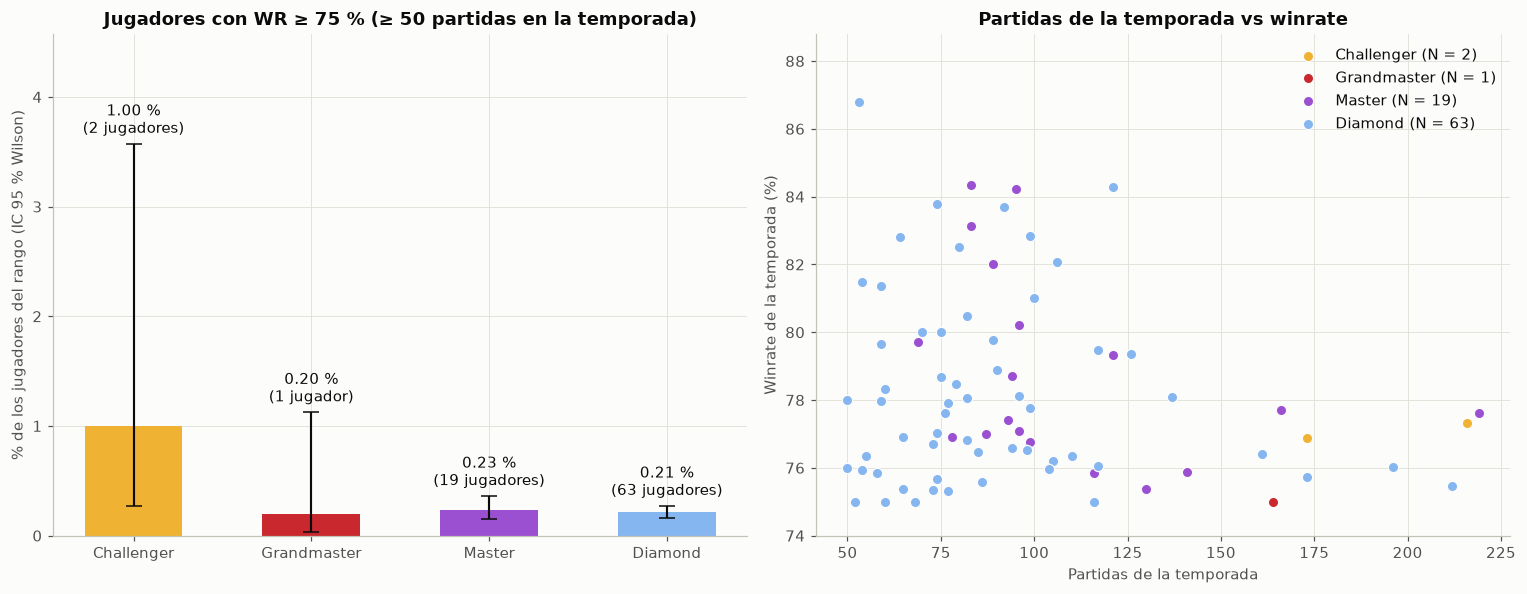

In [22]:
WR_MIN = 75.0
MIN_PARTIDAS_WR = 50
# Colores de los emblemas de rango del juego (Diamond conserva el de la paleta general)
COLORES_RANGO = {"CHALLENGER": "#F0B232", "GRANDMASTER": "#C8282E", "MASTER": "#9B4FD1",
                 "DIAMOND": TIER_COLORS["DIAMOND"]}

conn = sqlite3.connect(f"file:{(DATA_DIR / 'lol_las.db').resolve()}?mode=ro", uri=True, timeout=60.0)
try:
    df_p_sql = pd.read_sql_query(
        "SELECT puuid, tier, wins, losses FROM players WHERE wins + losses >= ?", conn, params=(MIN_PARTIDAS_WR,))
finally:
    conn.close()

df_p_sql["total_games"] = df_p_sql["wins"] + df_p_sql["losses"]
df_p_sql["winrate"] = 100 * df_p_sql["wins"] / df_p_sql["total_games"]
high_wr = df_p_sql[df_p_sql["winrate"] >= WR_MIN]
resumen_wr = (df_p_sql.groupby("tier").size().rename("con ≥ mín. partidas").to_frame()
              .join(high_wr.groupby("tier").size().rename(f"con WR ≥ {WR_MIN:.0f} %")).reindex(TIER_ORDER).fillna(0))
resumen_wr["% del rango"] = 100 * resumen_wr.iloc[:, 1] / resumen_wr.iloc[:, 0]
display(resumen_wr.round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
counts = resumen_wr.iloc[:, 1].astype(int)
totals_wr = resumen_wr.iloc[:, 0].astype(int)
pcts = resumen_wr["% del rango"]
lo_w, hi_w = wilson_ci(counts.to_numpy(float) / totals_wr.to_numpy(float), totals_wr.to_numpy(float))
lo_p, hi_p = 100.0 * lo_w, 100.0 * hi_w
bars = ax1.bar([t.capitalize() for t in TIER_ORDER], pcts, color=[COLORES_RANGO[t] for t in TIER_ORDER], width=0.55)
ax1.errorbar(np.arange(len(TIER_ORDER)), pcts.to_numpy(float),
             yerr=[np.maximum(0.0, pcts.to_numpy(float) - lo_p), np.maximum(0.0, hi_p - pcts.to_numpy(float))],
             fmt="none", ecolor=INK, elinewidth=1.4, capsize=5, zorder=5)
for bar, cnt, pct, hp in zip(bars, counts, pcts, hi_p):
    ax1.annotate(f"{pct:.2f} %\n({cnt} jugador{'es' if cnt != 1 else ''})", xy=(bar.get_x() + bar.get_width() / 2, hp),
                 xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9.5, color=INK)
ax1.set_ylim(0, max(float(hi_p.max()), 0.01) * 1.28)
ax1.set_title(f"Jugadores con WR ≥ {WR_MIN:.0f} % (≥ {MIN_PARTIDAS_WR} partidas en la temporada)")
ax1.set_ylabel("% de los jugadores del rango (IC 95 % Wilson)")

for t in TIER_ORDER:
    sub = high_wr[high_wr["tier"] == t]
    ax2.scatter(sub["total_games"], sub["winrate"], color=COLORES_RANGO[t], s=45, edgecolor="#fcfcfb",
                linewidth=0.8, label=f"{t.capitalize()} (N = {len(sub)})")
ax2.set_ylim(WR_MIN - 1, max(high_wr["winrate"].max(), WR_MIN) + 2)
ax2.set_title("Partidas de la temporada vs winrate")
ax2.set_xlabel("Partidas de la temporada")
ax2.set_ylabel("Winrate de la temporada (%)")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()